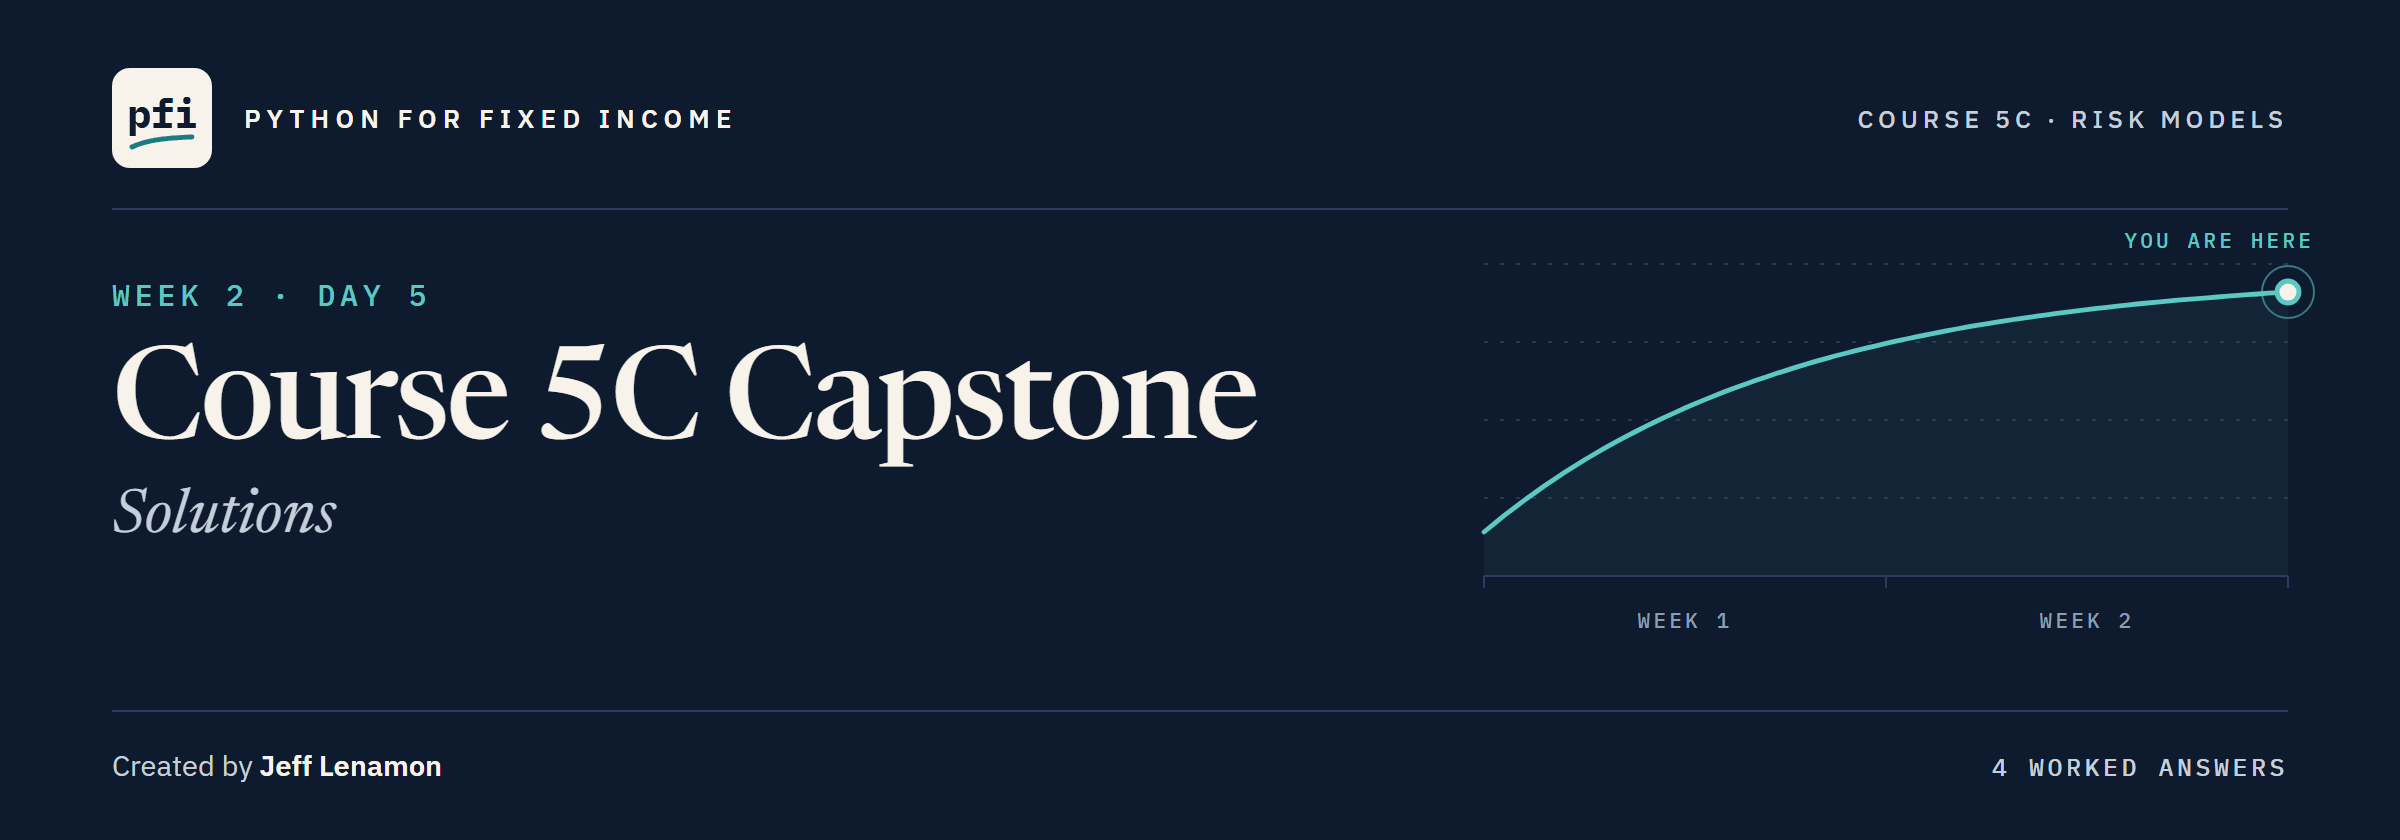

# Course 5C Capstone: Solutions

Week 2, Day 5. The full notebook with every exercise worked. Try each one yourself first.

**Data:** `holdings.csv`, the course's book of 200 bonds as of 2026-09-30, with `ratings.csv` for the rating scale: **synthetic**, invented issuers and CUSIPs, no real company.

**Data:** `treasury_par_yields.csv`, 2,940 days of U.S. Treasury par yields, 2015-01-02 to 2026-10-02: **real**, U.S. Department of the Treasury, public domain.

**Data:** `course3_synthetic_spreads.csv`, 2,940 daily investment grade and high yield spreads in bp, one per date of the Treasury file: **synthetic**, invented for Course 3, not ICE, Moody's, or any index.

**Data:** `trade_blotter.csv`, the desk's 374 trades in September 2026 in bonds of the book: **synthetic**, invented trades and counterparties.

**Data:** `course5c_cohort.csv`, 4,000 invented firms followed year by year over 20 study years to default, exit, or the end: **synthetic**, ids only, no calendar years, and no agency default statistic.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05c_risk_models/week2/day5/course5c_capstone_solutions.ipynb)

# Problem Statement

## Business Context

The risk team wants one report on the synthetic book, 200 bonds worth US$490.8m as of 2026-09-30, and on the synthetic cohort of firms.
It has five pieces: the book's market risk (Day 2), its credit loss (Day 3), a hazard model (Day 5), a screen of September's trades (Day 6), and drift (Day 8) read with Day 9's bands.
Every choice is made on the development rows, 2015 to 2022 and study years 1 to 14, and printed; then the held-out rows are opened once.
A VaR describes past days replayed on today's book, a credit loss invented inputs, and a flag a print to check: never what the book will lose.
Each question has an empty cell and a `check()` line.

## Objectives

Repeat the book's historical VaR and its credit loss, with each percentile's precision.
Choose a hazard model by a rule written first, and score a screen of planted prints.
Open the held-out years once, score each piece there, and measure drift with PSI.

![The report on one page: five pieces as rows (historical VaR, credit loss, hazard model, trade screen, drift by PSI) and three sittings as columns. Sitting one builds each piece on the development rows. Sitting two prints every choice, from the fixed and rolling VaR to the PSI bins and floor. Sitting three opens the held-out rows once and scores each piece there. The trade screen has nothing held out, as its planted labels score it.](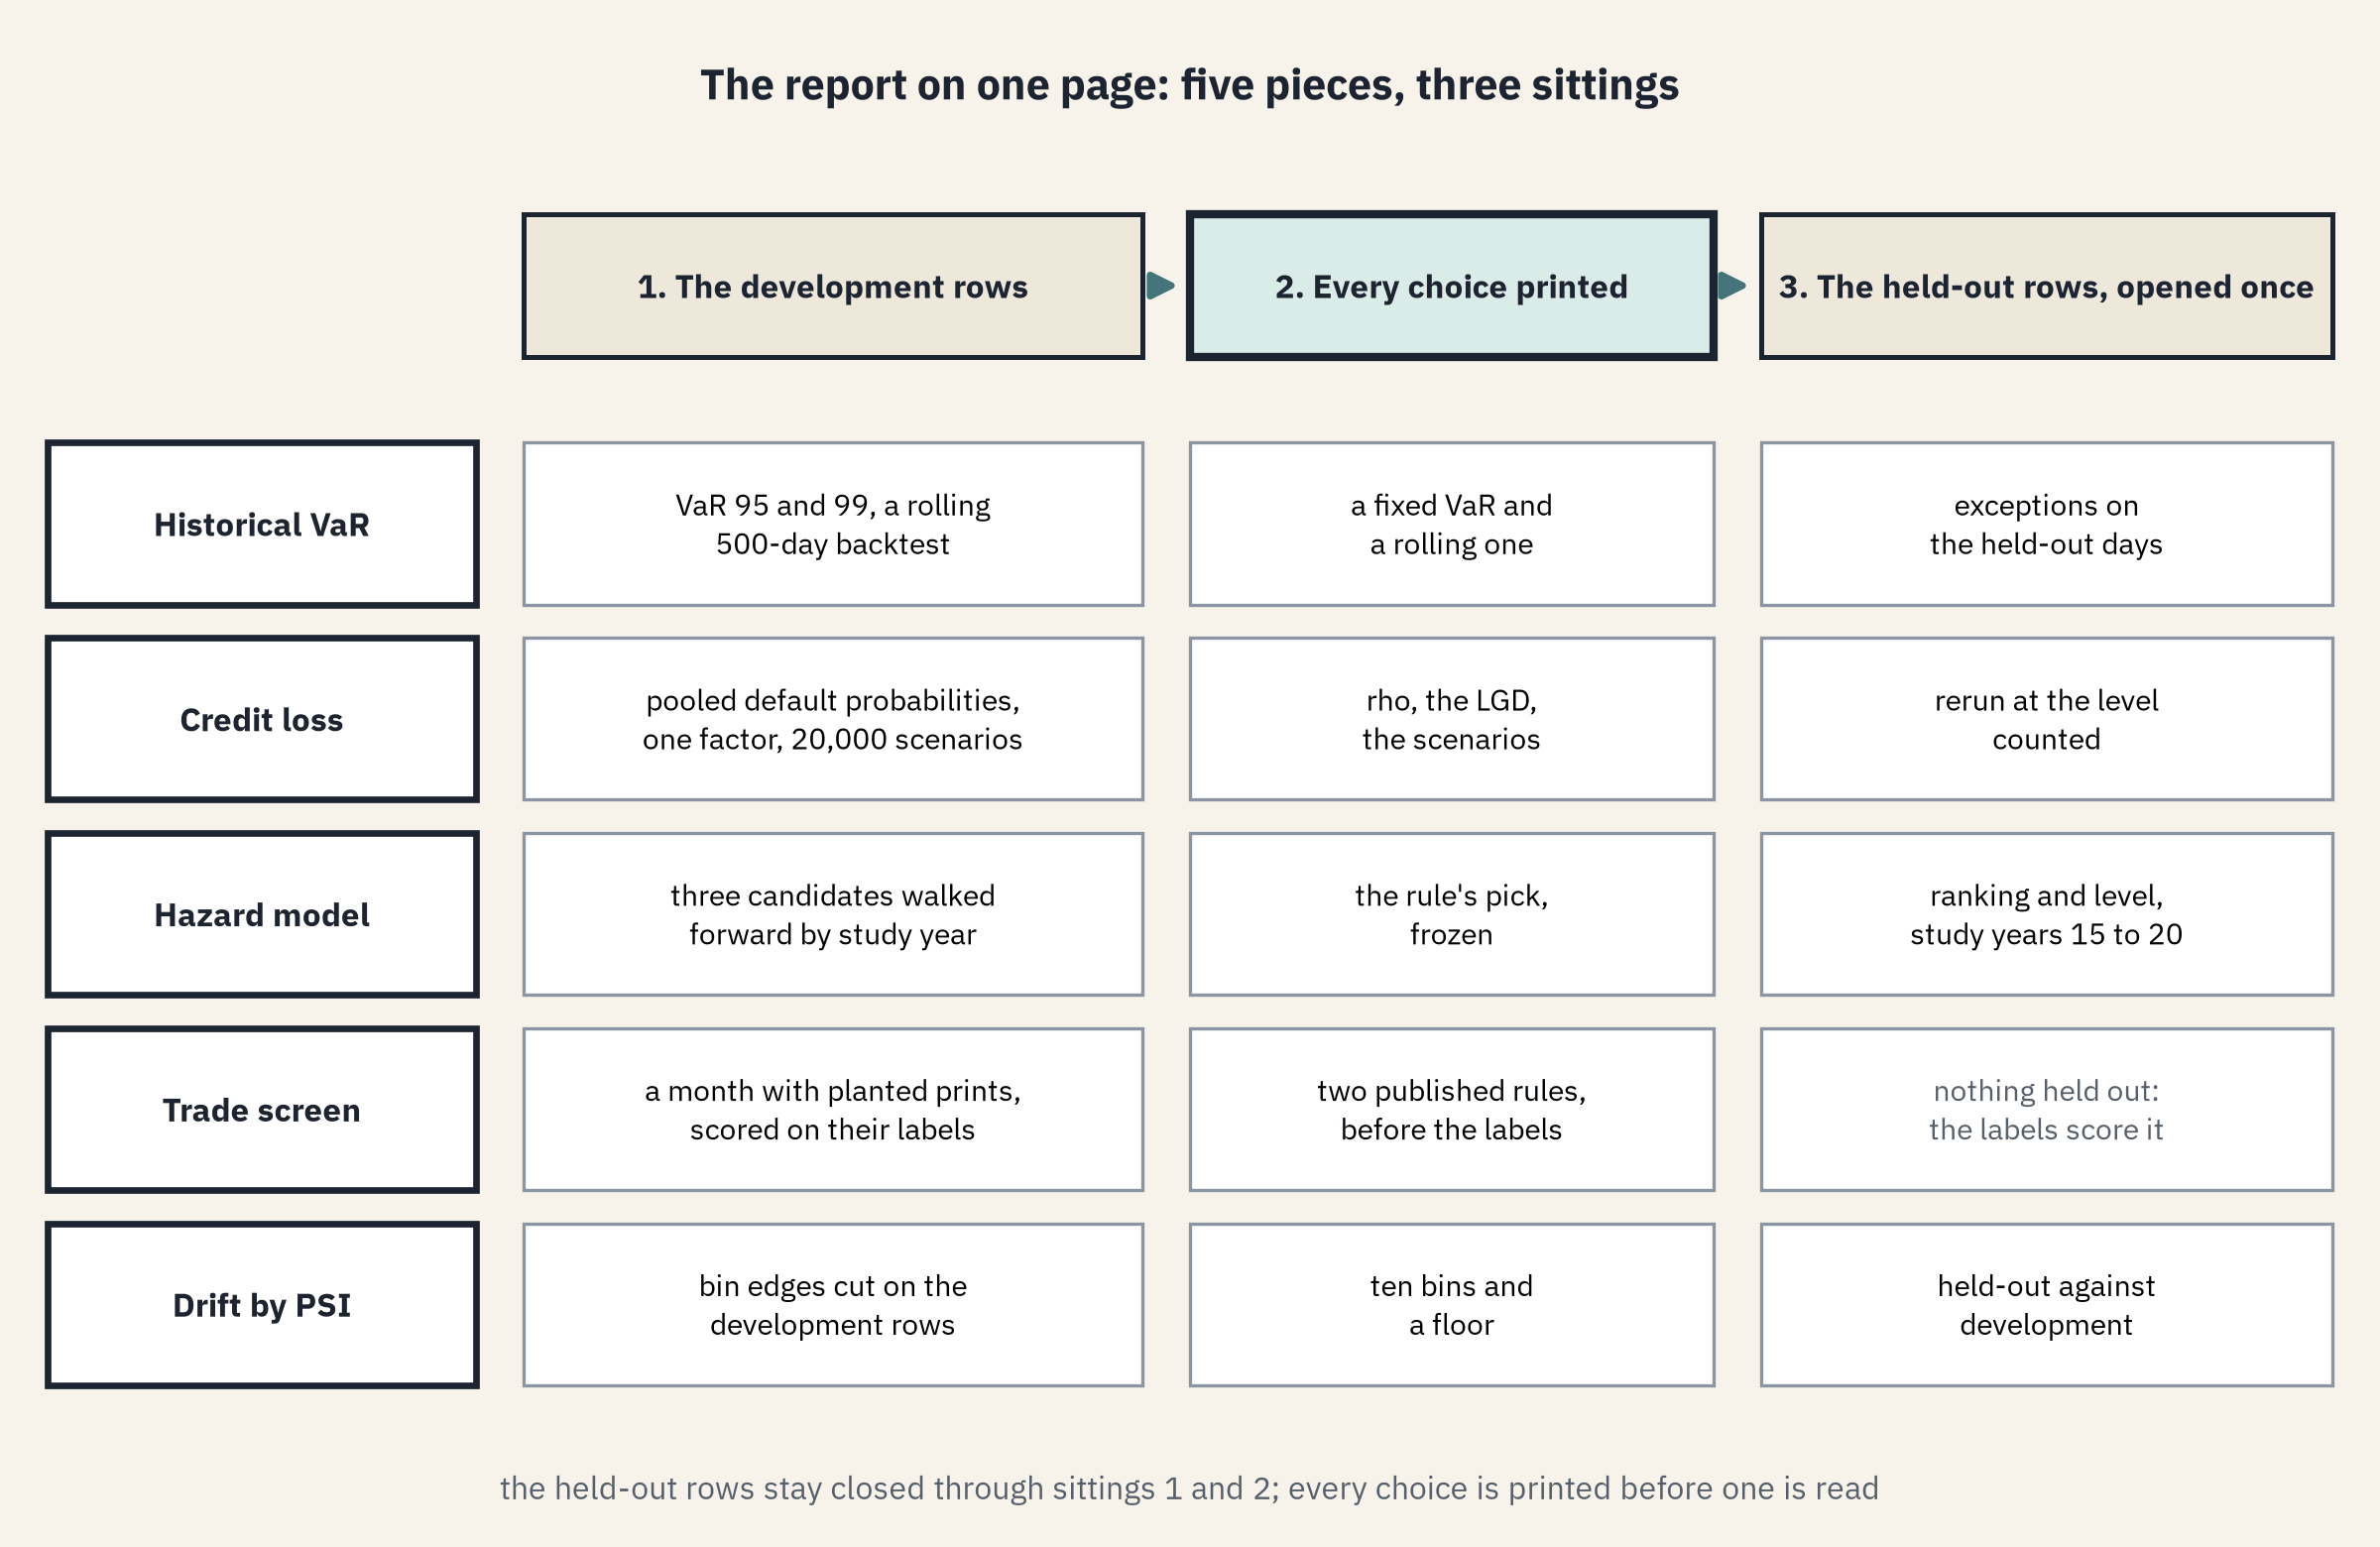)

## Data Dictionary

`holdings.csv` with `ratings.csv`: each bond's `rating`, `oas` (bp), durations (years) and `market_value` (US$).
`treasury_par_yields.csv`: par yields in percent; `course3_synthetic_spreads.csv`: two spreads in bp.
`trade_blotter.csv`: one row a trade, with its `price`.
`course5c_cohort.csv`: one row a firm-year, with `rating_score`, `leverage`, `coverage` and `default`.

# Setting Up

## Course Setup

Run this cell and move on: it fixes the seed and finds the course data.

In [1]:
# today's setup: the thread settings, the seed, and where the course data lives
import os
from pathlib import Path

# one thread for the maths libraries, so every run prints the same last digits (this must run before numpy is imported)
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

# the seed: one number for every random choice, so every run makes the same choices
SEED = 42

# the course data: the repo's data folder on your machine, GitHub in Colab
DATA = "../../../data/"
if not Path(DATA + "benchmark.csv").exists():
    DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"

## Importing the Libraries

In [2]:
# to load and work with the data
import numpy as np
import pandas as pd

# the normal, binomial, chi-squared and Poisson curves, and the logistic fit
from scipy import stats
import statsmodels.api as sm

# the AUC (Course 4's Day 8) and the screen's scores (Day 6)
from sklearn.metrics import roc_auc_score, confusion_matrix, precision_score, recall_score, f1_score

# to draw charts
import matplotlib.pyplot as plt
import seaborn as sns

# one look for every chart
sns.set_theme(style="whitegrid")
sns.set_palette("colorblind")
# one colour for each of the four kinds of row a confusion matrix counts
CELL_COLOURS = {"TN": "#56B4E9", "FP": "#DE8F05", "FN": "#D55E00", "TP": "#0173B2"}
plt.rcParams["figure.figsize"] = (10, 5)

## The Answer Checker

`check()` compares a fingerprint of each answer with a stored one, so no answer is on the page; a US$ sum is checked to the dollar.

In [3]:
# check() compares a fingerprint of your answer with a stored one, so no answer is written on the page
import hashlib


def check(label, answer, code, places=None):
    if answer is ...:
        print(label + ": not attempted yet")
        return
    # a number is rounded to the places the question asks for, so 0.66241 and 0.6624 read the same
    if places is not None:
        answer = round(float(answer), places)
    text = label + "|" + str(answer).strip().lower()
    # hashlib.sha256() makes a fingerprint that cannot be turned back into the answer;
    # .encode() turns the text into bytes for it, and .hexdigest() writes it as letters and digits
    if hashlib.sha256(text.encode()).hexdigest()[:12] == code:
        print(label + ": correct")
    else:
        print(label + ": not yet. You have " + str(answer))

# Loading the Data

## The Five Files and the Two Cuts

In [4]:
# the book of 200 synthetic bonds as of 2026-09-30, with each bond's score, bucket and grade from the rating scale
book = pd.read_csv(DATA + "holdings.csv")
ratings = pd.read_csv(DATA + "ratings.csv")
book = book.merge(ratings[["rating", "score", "bucket", "grade"]], on="rating")
book["years_to_maturity"] = (pd.to_datetime(book["maturity"]) - pd.to_datetime(book["as_of_date"])).dt.days / 365.25

In [5]:
# the Treasury par yields (percent), eight tenors named by their years, and the synthetic spreads (bp)
treasury = pd.read_csv(DATA + "treasury_par_yields.csv", parse_dates=["date"], index_col="date")
spreads = pd.read_csv(DATA + "course3_synthetic_spreads.csv", parse_dates=["date"], index_col="date")
TENORS = {"1 Yr": 1, "2 Yr": 2, "3 Yr": 3, "5 Yr": 5, "7 Yr": 7, "10 Yr": 10, "20 Yr": 20, "30 Yr": 30}
curve = treasury[list(TENORS)].rename(columns=TENORS)

# Course 5B's cut: every choice is made on the dates to 2022-12-30; the later dates are counted, never read
CUT = "2022-12-30"
dev_curve, dev_spreads = curve.loc[:CUT], spreads.loc[:CUT]
print("Development dates:", len(dev_curve), "| held-out dates, closed:", (curve.index > CUT).sum())

Development dates: 2001 | held-out dates, closed: 939


In [6]:
# the synthetic trades of September 2026, and the synthetic cohort of invented firms
blotter = pd.read_csv(DATA + "trade_blotter.csv")
cohort = pd.read_csv(DATA + "course5c_cohort.csv")

# Day 3's split: development study years 1 to 14; the later years are counted, never read
DEVELOPMENT_END = 14
development = cohort[cohort["study_year"] <= DEVELOPMENT_END].copy()
print("Trades:", len(blotter), "| development firm-years:", len(development), "| held-out firm-years, closed:", len(cohort) - len(development))

Trades: 374 | development firm-years: 18503 | held-out firm-years, closed: 11112


![The rows' roles. The curve and spreads have 2,001 development dates, 2015-01-02 to 2022-12-30, read from the start, and 939 held-out dates after the cut, closed. The cohort has study years 1 to 14, 18,503 firm-years, read, and study years 15 to 20, 11,112 firm-years, closed. The trades are 374 trades of September 2026, then a copy with planted prints, then labels that only score. The book is 200 bonds as of 2026-09-30, held fixed under every past day and every scenario.](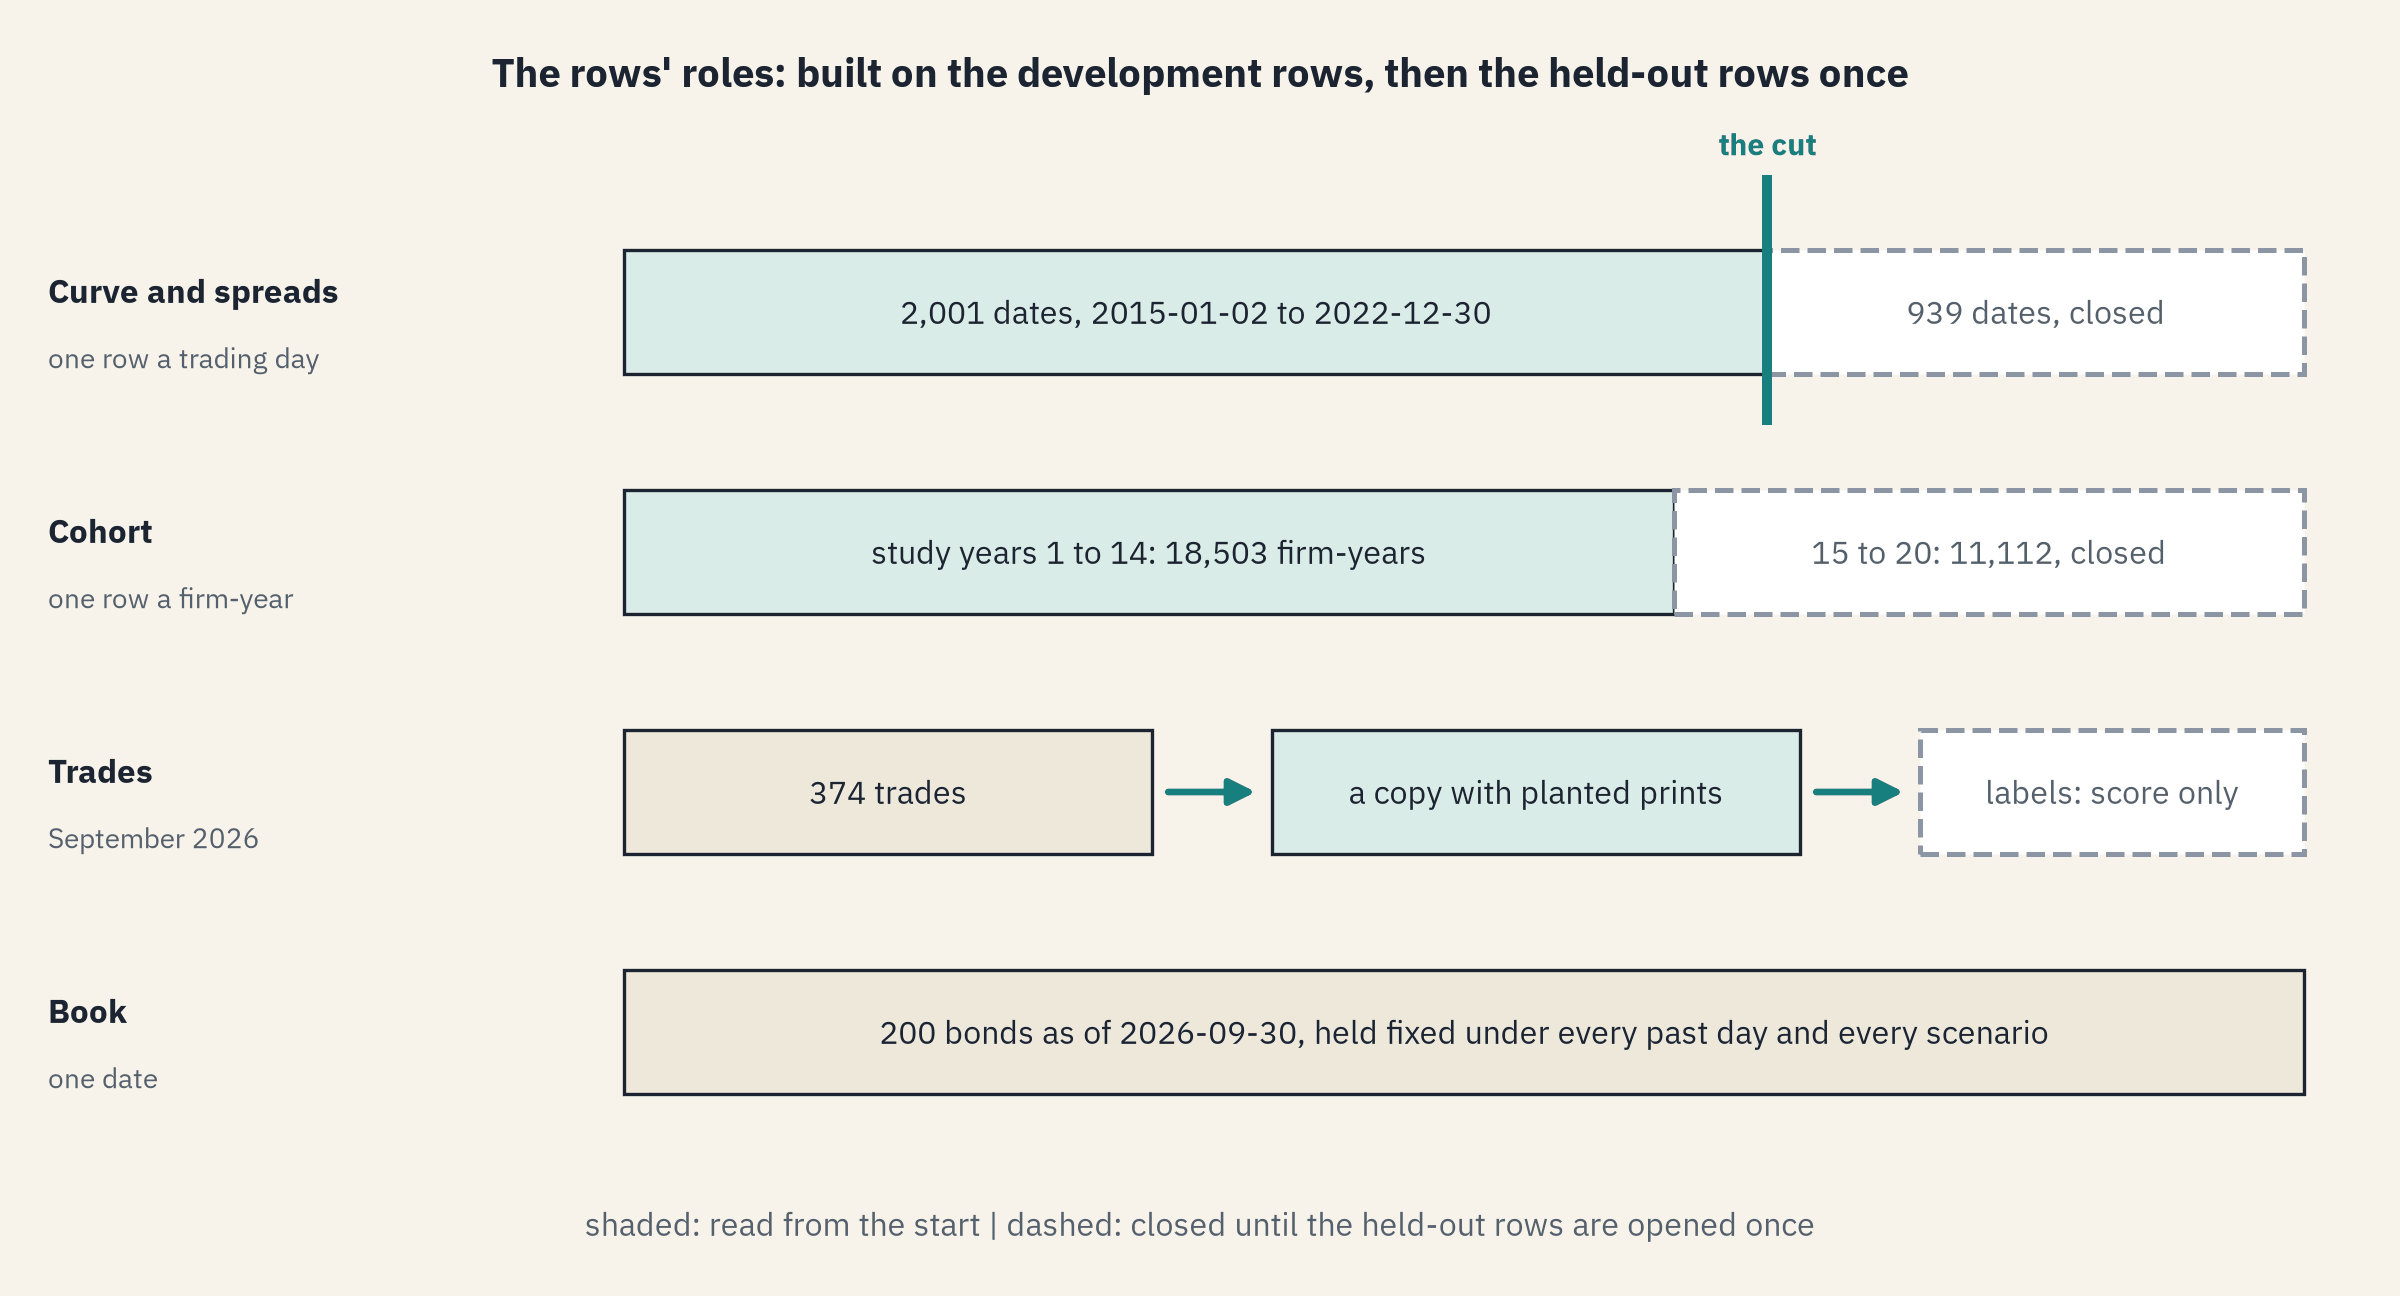)

**Every held-out row stays closed until the choices are printed.**

# Data Overview

## The Book and the Cohort

Q. Store the book's high-yield market value (US$) and its number of bonds: `q1_hy_value`, `q1_hy_bonds`.

Q. Store the development years' defaults and counted default rate (percent a year, 2 decimals): `q2_defaults`, `q2_rate`.

In [7]:
# the high-yield part of the book, in US$
high_yield = book[book["grade"] == "High Yield"]
q1_hy_value, q1_hy_bonds = high_yield["market_value"].sum(), len(high_yield)
print(f"High yield: {q1_hy_bonds} of {len(book)} bonds, US${q1_hy_value:,.0f} of US${book['market_value'].sum():,.0f}")

High yield: 72 of 200 bonds, US$169,901,850 of US$490,819,215


In [8]:
# the development years' firms, defaults and exits, and the counted default rate per firm-year
q2_defaults, q2_rate = development["default"].sum(), 100 * development["default"].mean()
print("Firms:", development["firm_id"].nunique(), "| defaults:", q2_defaults, "| exits:", development["exit"].sum(), f"| counted rate {q2_rate:.2f} percent a year")

Firms: 3504 | defaults: 345 | exits: 1231 | counted rate 1.86 percent a year


In [9]:
check("Q1 high-yield market value", q1_hy_value, "c12741dc394e", places=0)
check("Q1 high-yield bonds", q1_hy_bonds, "0eabafed2276", places=0)
check("Q2 development defaults", q2_defaults, "2c2b7062c81f", places=0)
check("Q2 counted default rate", q2_rate, "76894ddfba2c", places=2)

Q1 high-yield market value: correct
Q1 high-yield bonds: correct
Q2 development defaults: correct
Q2 counted default rate: correct


## The Development Curve, Quarter by Quarter

A **candlestick** draws a quarter as a wick from its lowest to its highest daily level, and a body from its first level to its last.
Day 8's `.index.to_period("Q")` names each day's quarter, and `groupby` gathers them.
The ruler is each tenor's nine decile edges of the development levels, cut now.

In [10]:
# each development quarter's first, highest, lowest and last daily level, for the 2 Yr and the 10 Yr
quarters = {tenor: dev_curve[tenor].groupby(dev_curve.index.to_period("Q")).agg(["first", "max", "min", "last"]) for tenor in [2, 10]}

# the ruler: each tenor's nine decile edges of the development levels, cut before any held-out value
ruler = {tenor: np.quantile(dev_curve[tenor], np.arange(1, 10) / 10) for tenor in [2, 10]}
closed = curve.index[curve.index > CUT].to_period("Q").nunique()
print(len(quarters[10]), "development quarters |", closed, "held-out quarters, closed")
for tenor in [2, 10]:
    print(f"{tenor} Yr: {dev_curve[tenor].min()} to {dev_curve[tenor].max()} percent | edges {ruler[tenor].round(2)}")

32 development quarters | 16 held-out quarters, closed
2 Yr: 0.09 to 4.72 percent | edges [0.16 0.41 0.67 0.8  1.21 1.45 1.8  2.45 2.76]
10 Yr: 0.52 to 4.25 percent | edges [0.95 1.54 1.71 1.87 2.12 2.27 2.42 2.75 2.97]


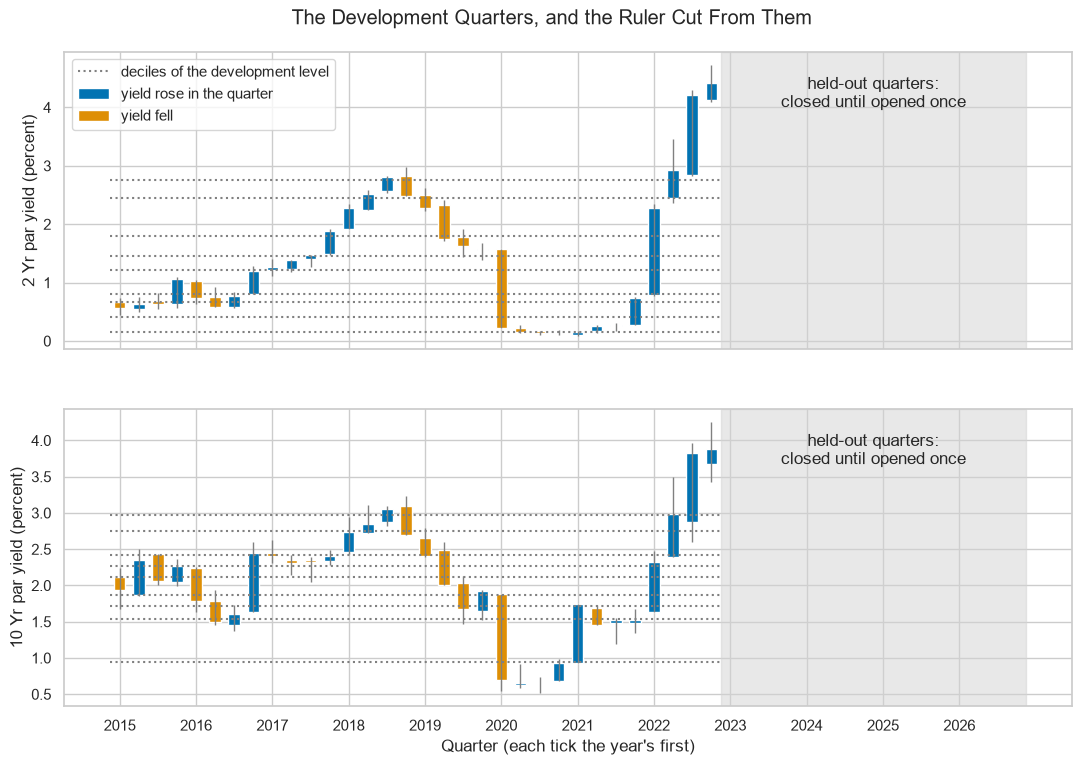

In [11]:
# a candlestick a quarter, the body coloured by direction; the ruler dotted; the held-out quarters a blank band
fig, axes = plt.subplots(2, 1, figsize=(13, 8.5), sharex=True)
for ax, tenor in zip(axes, [2, 10]):
    q, x = quarters[tenor], np.arange(len(quarters[tenor]))
    ax.vlines(x, q["min"], q["max"], color="gray", linewidth=1)
    for rose, colour, label in [(q["last"] >= q["first"], "C0", "yield rose in the quarter"), (q["last"] < q["first"], "C1", "yield fell")]:
        ax.bar(x[rose], (q["last"] - q["first"])[rose], bottom=q["first"][rose], width=0.6, color=colour, label=label)
    ax.hlines(ruler[tenor], -0.5, len(x) - 0.5, color="gray", linestyle=":", label="deciles of the development level")
    ax.axvspan(len(x) - 0.5, len(x) - 0.5 + closed, color="lightgray", alpha=0.5)
    # get_xaxis_transform: x in data, y as a share of the axis height
    ax.text(len(x) - 0.5 + closed / 2, 0.92, "held-out quarters:\nclosed until opened once", ha="center", va="top", transform=ax.get_xaxis_transform())
    ax.set(ylabel=f"{tenor} Yr par yield (percent)")
axes[0].legend(loc="upper left")
axes[1].set_xticks(np.arange(0, len(quarters[10]) + closed, 4), range(2015, 2027))
axes[1].set_xlabel("Quarter (each tick the year's first)")
fig.suptitle("The Development Quarters, and the Ruler Cut From Them", y=0.93)
plt.show()

The 10 Yr ran from 0.52 to 4.25 percent, the 2 Yr from 0.09 to 4.72.

By the end of 2022 both sat above every edge of their rulers.

**One book, one cohort, one month of trades, and a ruler fixed on the development years.**

# The Book's Market Risk

Day 2's workflow, and one dictionary, `choices`, that takes each choice where it is made.

In [12]:
# every choice goes into one dictionary where it is made; it is printed before a held-out row is read
choices = {"VaR": {"levels": [0.95, 0.99], "fixed": "the development days", "rolling window": 500}}

## Two Lists of Sensitivities

Q. Repeat Day 2's key-rate DV01s (`key_rate_dv01`, by tenor in years) and DTS by index (`dts_by_index`, keyed by spread column). Store their sum and the HY DTS (US$): `q3_dv01`, `q3_hy_dts`.

In [13]:
# DV01 and DTS in US$, as Day 2 wrote them
book["dv01"] = book["market_value"] * book["duration"] / 10_000
book["dts_usd"] = book["market_value"] * book["spread_duration"] / 10_000 * book["oas"] / 100

# hat weights: one row of np.eye(8) read at each bond's maturity; then the key-rate DV01s
years = list(TENORS.values())
weights = pd.DataFrame({tenor: np.interp(book["years_to_maturity"], years, row) for tenor, row in zip(years, np.eye(8))})
key_rate_dv01 = weights.T @ book["dv01"]

In [14]:
# the two spread sensitivities, named by the spread column each one meets
dts_by_index = pd.Series({"ig_spread_bp": book.loc[book["grade"] == "Investment Grade", "dts_usd"].sum(),
                          "hy_spread_bp": book.loc[book["grade"] == "High Yield", "dts_usd"].sum()})
q3_dv01, q3_hy_dts = key_rate_dv01.sum(), dts_by_index["hy_spread_bp"]
print(f"Key-rate DV01s sum to US${q3_dv01:,.0f} per bp | DTS: IG US${dts_by_index['ig_spread_bp']:,.0f}, HY US${q3_hy_dts:,.0f}")

Key-rate DV01s sum to US$306,996 per bp | DTS: IG US$224,130, HY US$298,157


In [15]:
check("Q3 key-rate DV01s", q3_dv01, "4976db78a16c", places=0)
check("Q3 HY DTS", q3_hy_dts, "c20556fe6aba", places=0)

Q3 key-rate DV01s: correct
Q3 HY DTS: correct


## 2,000 Days on Today's Book

Q. Replay the development days on the book as Day 2 did, `loss = -pnl` in US$, with Day 2's `var_es`. Store the 99 percent VaR and ES and the 95 percent VaR (US$): `q4_var99`, `q4_es99`, `q4_var95`.

In [16]:
# each development day's moves: rates in bp, spreads in percent of the day before
rate_moves = (dev_curve.diff() * 100).dropna()
spread_moves = (dev_spreads.pct_change() * 100).dropna()

# each day's P&L on today's book, a rise a loss; the course's sign makes a loss positive
pnl = -(rate_moves @ key_rate_dv01) - (spread_moves[dts_by_index.index] @ dts_by_index)
loss = -pnl

In [17]:
# Day 2's VaR and expected shortfall of a series of losses
def var_es(loss, level):
    """VaR and expected shortfall of a series of losses, a loss positive."""
    var = np.quantile(loss, level)
    return var, loss[loss >= var].mean()

q4_var99, q4_es99 = var_es(loss, 0.99)
q4_var95 = var_es(loss, 0.95)[0]
print(f"{len(loss):,} days | VaR 99 US${q4_var99:,.0f}, ES US${q4_es99:,.0f} | VaR 95 US${q4_var95:,.0f} | sd US${loss.std():,.0f}")

2,000 days | VaR 99 US$4,490,319, ES US$5,790,757 | VaR 95 US$2,816,546 | sd US$1,726,060


In [18]:
check("Q4 VaR 99", q4_var99, "26bc0660f971", places=0)
check("Q4 ES 99", q4_es99, "d45bc4a0b825", places=0)
check("Q4 VaR 95", q4_var95, "0bccbe62ef98", places=0)

Q4 VaR 99: correct
Q4 ES 99: correct
Q4 VaR 95: correct


## The Rolling VaR Inside Development

Q. Walk Day 2's rolling 500-day 99 percent VaR over the development losses, and run Day 2's `kupiec`. Store the exceptions and the p-value (4 decimals): `q5_exceptions`, `q5_p`.

Q. Draw the losses, the VaR and the exceptions, and the exceptions by year.

In [19]:
# each day's 99 percent VaR from the 500 losses before it, and the days beyond it
var_99 = loss.rolling(500).quantile(0.99).shift(1)
tested = var_99.dropna().index
exceptions = loss[tested] > var_99[tested]

In [20]:
# Day 2's Kupiec test
def kupiec(x, n, level):
    """Kupiec's likelihood ratio and p-value for x exceptions in n days at a VaR level."""
    lr = 2 * np.log(stats.binom.pmf(x, n, x / n) / stats.binom.pmf(x, n, 1 - level))
    return lr, stats.chi2.sf(lr, 1)

q5_exceptions = exceptions.sum()
q5_p = kupiec(q5_exceptions, len(tested), 0.99)[1]
print(f"{q5_exceptions} exceptions in {len(tested):,} days from {tested[0].date()} | expected {0.01 * len(tested):.0f} | Kupiec p {q5_p:.4f}")

28 exceptions in 1,500 days from 2017-01-03 | expected 15 | Kupiec p 0.0026


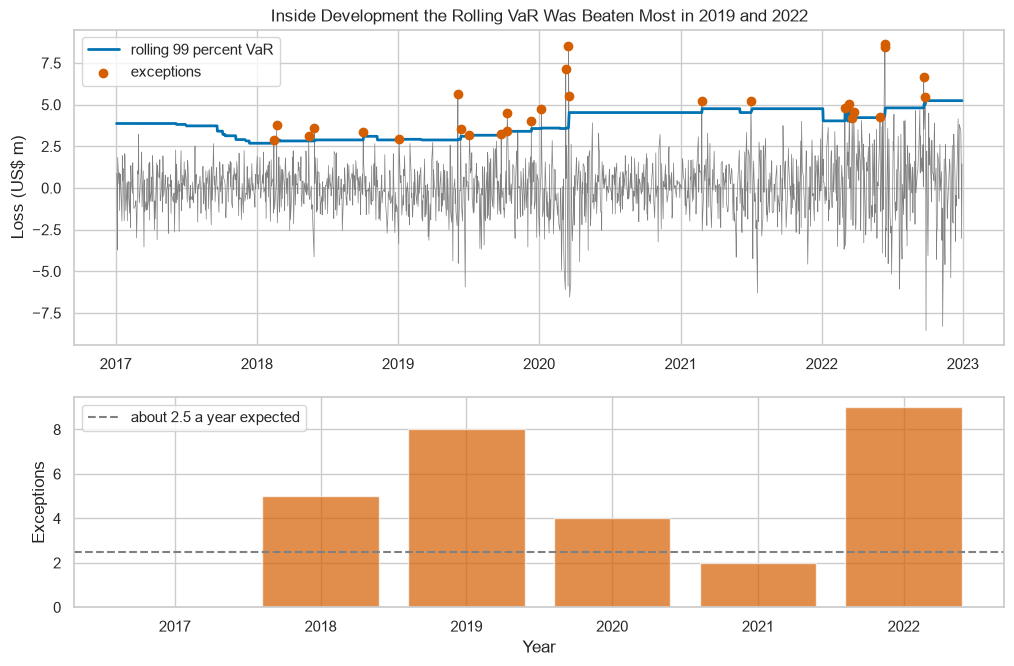

In [21]:
# the losses, the rolling VaR and the exceptions; then the exceptions by year against 2.5
by_year = exceptions.groupby(exceptions.index.year).sum()
fig, (top, bottom) = plt.subplots(2, 1, figsize=(12, 7.5), height_ratios=[3, 2])
top.plot(tested, loss[tested] / 1e6, linewidth=0.5, color="gray")
top.plot(tested, var_99[tested] / 1e6, color="C0", linewidth=2, label="rolling 99 percent VaR")
top.scatter(tested[exceptions], loss[tested][exceptions] / 1e6, color="C3", zorder=3, label="exceptions")
top.set(ylabel="Loss (US$ m)", title="Inside Development the Rolling VaR Was Beaten Most in 2019 and 2022")
top.legend(loc="upper left")
bottom.bar(by_year.index, by_year, color="C3", alpha=0.7)
bottom.axhline(2.5, color="gray", linestyle="--", label="about 2.5 a year expected")
bottom.set(xlabel="Year", ylabel="Exceptions")
bottom.legend()
plt.show()

In [22]:
check("Q5 rolling exceptions", q5_exceptions, "b036e55290c8", places=0)
check("Q5 Kupiec p-value", q5_p, "0c0baeb8d2d7", places=4)

Q5 rolling exceptions: correct
Q5 Kupiec p-value: correct


**Two VaRs go forward, the fixed development one and the rolling one; the held-out days score both.**

# The Book's Credit Loss

## A Default Probability for Every Bond

Q. Fit Day 3's pooled `sm.Logit` of `default` on `rating_score` as `pooled`, give each bond its `default_prob`, and take Day 3's expected loss at `LGD_MEAN = 0.60`. Store the slope and the mean probability in percent a year (4 decimals), and the expected loss (US$): `q6_slope`, `q6_mean_prob`, `q6_el`.

In [23]:
# Day 3's pooled fit: the log odds of a default in the year on the rating score
pooled = sm.Logit(development["default"], sm.add_constant(development[["rating_score"]])).fit(disp=0)

# each bond's probability at its score, and Day 1's expected loss, PD x LGD x EAD, in US$
book["default_prob"] = pooled.predict(sm.add_constant(book[["score"]].rename(columns={"score": "rating_score"})))
LGD_MEAN = 0.60
q6_slope, q6_mean_prob = pooled.params["rating_score"], 100 * book["default_prob"].mean()
q6_el = (book["default_prob"] * LGD_MEAN * book["market_value"]).sum()
print(f"Slope {q6_slope:.4f} | mean probability {q6_mean_prob:.4f} percent a year | expected loss US${q6_el:,.0f}")

Slope 0.4967 | mean probability 1.1676 percent a year | expected loss US$3,482,412


In [24]:
check("Q6 slope", q6_slope, "06fe4e018664", places=4)
check("Q6 mean probability", q6_mean_prob, "c91ed457426a", places=4)
check("Q6 expected loss", q6_el, "f895e048bb30", places=0)

Q6 slope: correct
Q6 mean probability: correct
Q6 expected loss: correct


## 20,000 Scenarios

Q. Repeat Day 3's `one_factor_defaults`, and write `credit_losses(default_prob, n_sims, rng)` at Day 3's `RHO = 0.20` and `rng.beta(6, 4)` LGDs. Run 20,000 scenarios from `default_rng(SEED)` as `losses`, and add the credit entry to `choices`. Store the mean and 99.9 percent VaR (US$), and the share with no default (3 decimals): `q7_mean`, `q7_var999`, `q7_none`.

A **quantile dot plot** stacks 100 dots, the quantiles at (i - 0.5) / 100, in US$1m bins: each dot is one chance in 100.

Q. Draw one for `losses`, the dots beyond the 99 percent VaR in the accent colour.

In [25]:
# Day 3's one-factor draw
def one_factor_defaults(default_prob, rho, n_sims, rng):
    """Defaults in each scenario (rows) for each bond (columns), through one common factor."""
    common = rng.standard_normal((n_sims, 1))
    own = rng.standard_normal((n_sims, len(default_prob)))
    return np.sqrt(rho) * common + np.sqrt(1 - rho) * own < stats.norm.ppf(default_prob)

# the book's loss in each scenario, at Day 3's inputs
RHO = 0.20
mv = book["market_value"].to_numpy()
def credit_losses(default_prob, n_sims, rng):
    """The book's credit loss in US$ in each of n_sims scenarios: one factor at RHO, beta(6, 4) LGDs."""
    defaults = one_factor_defaults(default_prob, RHO, n_sims, rng)
    return (defaults * rng.beta(6, 4, defaults.shape) * mv).sum(axis=1)

In [26]:
# one run of 20,000: the mean with Day 1's standard error, then the VaR and ES at three levels, in US$
losses = credit_losses(book["default_prob"].to_numpy(), 20_000, np.random.default_rng(SEED))
q7_mean, q7_none, q7_var999 = losses.mean(), (losses == 0).mean(), var_es(losses, 0.999)[0]
print(f"Mean US${q7_mean:,.0f} (standard error US${losses.std(ddof=1) / np.sqrt(len(losses)):,.0f}) | no default in {100 * q7_none:.1f} percent of scenarios")
for level, name in [(0.95, "95"), (0.99, "99"), (0.999, "99.9")]:
    print(f"{name} percent: VaR US${var_es(losses, level)[0]:,.0f} | ES US${var_es(losses, level)[1]:,.0f}")
print("Percentiles from one run of 20,000; how far a rerun moves them is the next question.")
choices["credit"] = {"probabilities": "the pooled fit", "rho": RHO, "LGD": "beta(6, 4)", "scenarios": 20_000}

Mean US$3,455,402 (standard error US$32,569) | no default in 29.2 percent of scenarios
95 percent: VaR US$12,296,958 | ES US$17,883,909
99 percent: VaR US$21,138,890 | ES US$27,571,254
99.9 percent: VaR US$36,203,254 | ES US$45,158,522
Percentiles from one run of 20,000; how far a rerun moves them is the next question.


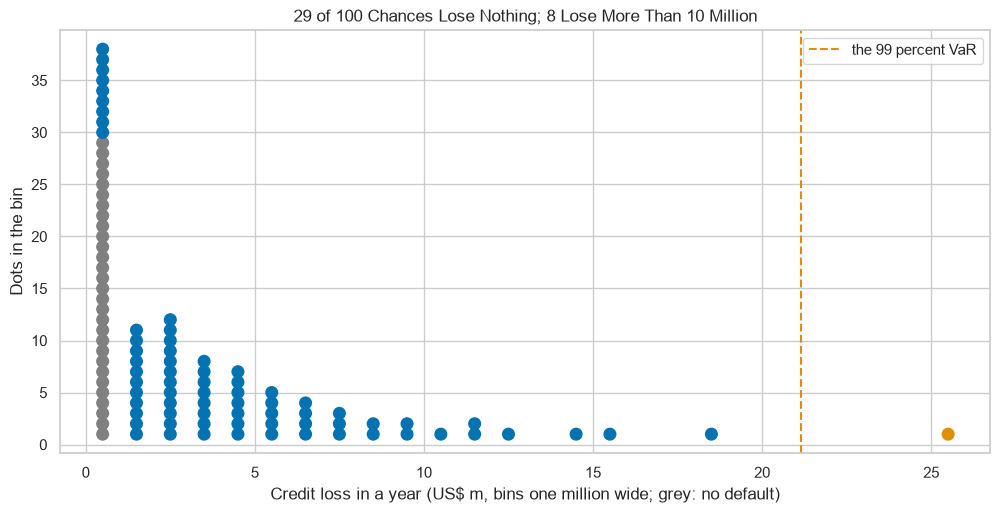

In [27]:
# the 100 dots, each stacked in its US$1m bin; np.floor rounds down, as math.floor does, and cumcount numbers the dots in a bin from 0
dots = np.quantile(losses, (np.arange(1, 101) - 0.5) / 100) / 1e6
bins = np.floor(dots)
height = pd.Series(bins).groupby(bins).cumcount().to_numpy() + 1
colour = np.where(dots >= var_es(losses, 0.99)[0] / 1e6, "C1", np.where(dots == 0, "gray", "C0"))
fig, ax = plt.subplots(figsize=(12, 5.5))
ax.scatter(bins + 0.5, height, s=70, color=colour)
ax.axvline(var_es(losses, 0.99)[0] / 1e6, color="C1", linestyle="--", label="the 99 percent VaR")
ax.set(xlabel="Credit loss in a year (US$ m, bins one million wide; grey: no default)", ylabel="Dots in the bin",
       title=f"{(dots == 0).sum()} of 100 Chances Lose Nothing; {(dots > 10).sum()} Lose More Than 10 Million")
ax.legend()
plt.show()

Read as dots, a year loses nothing in 29 chances of 100 and more than US$10m in 8.

In [28]:
check("Q7 mean loss", q7_mean, "60297a3428d4", places=0)
check("Q7 VaR 99.9", q7_var999, "13e2bc74b37a", places=0)
check("Q7 share with no default", q7_none, "d8597cf79673", places=3)

Q7 mean loss: correct
Q7 VaR 99.9: correct
Q7 share with no default: correct


**Predict 1**

Day 3's ten runs of 50,000 put the standard deviation of the 99.9 percent VaR at US$0.91m.

Q. For ten runs of 20,000 with the same inputs, what standard deviation? Write down a number in US$ m.

## How Sure the 99.9 Percent Loss Is

Q. Rerun `credit_losses` ten times from `np.random.default_rng(SEED).spawn(10)`, a table `runs` of the VaR and ES at 99 and 99.9 percent (US$ m). Store the 99.9 percent VaR's standard deviation (US$): `q8_sd999`.

Q. Draw the runs as strips, Q7's run ringed.

In [29]:
# ten runs of 20,000, each from its own child of SEED, in US$ m
run_rows = []
for child in np.random.default_rng(SEED).spawn(10):
    run = credit_losses(book["default_prob"].to_numpy(), 20_000, child)
    run_rows.append({"VaR 99": var_es(run, 0.99)[0], "ES 99": var_es(run, 0.99)[1], "VaR 99.9": var_es(run, 0.999)[0], "ES 99.9": var_es(run, 0.999)[1]})
runs = pd.DataFrame(run_rows) / 1e6
q8_sd999 = runs["VaR 99.9"].std() * 1e6
runs.agg(["min", "max", "std"]).round(2)

,VaR 99,ES 99,VaR 99.9,ES 99.9
min,20.64,26.55,32.43,39.27
max,21.55,27.96,37.83,46.54
std,0.30,0.45,1.47,2.21


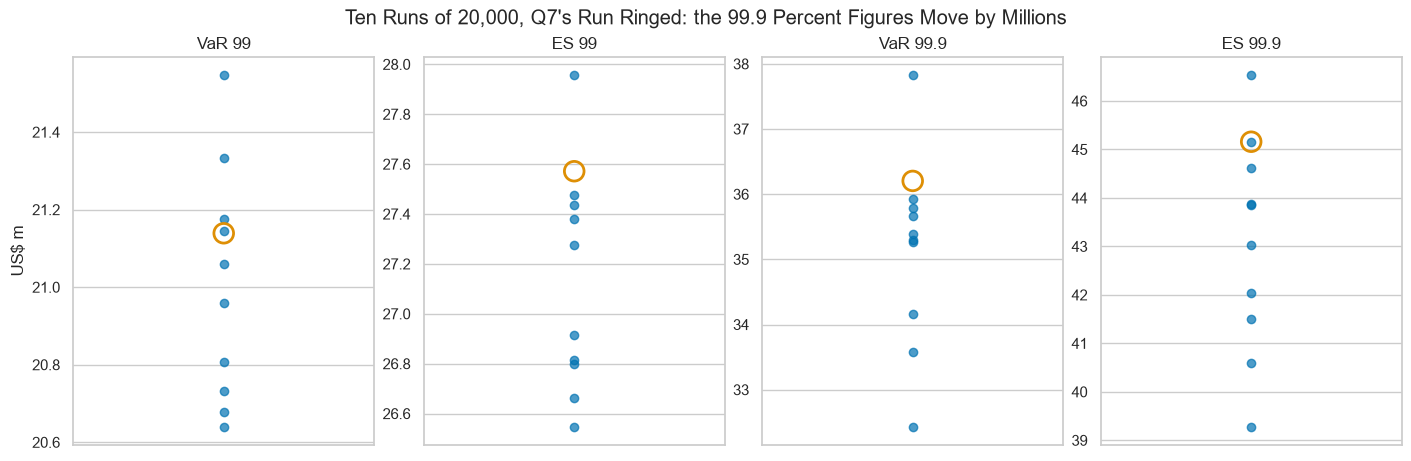

In [30]:
# the ten runs as strips, Q7's run ringed
main = {"VaR 99": var_es(losses, 0.99)[0], "ES 99": var_es(losses, 0.99)[1], "VaR 99.9": q7_var999, "ES 99.9": var_es(losses, 0.999)[1]}
fig, axes = plt.subplots(1, 4, figsize=(14, 4.5), layout="constrained")
for ax, name in zip(axes, runs.columns):
    ax.scatter(np.zeros(10), runs[name], color="C0", alpha=0.7)
    ax.scatter(0, main[name] / 1e6, s=200, facecolors="none", edgecolors="C1", linewidths=2)
    ax.set(title=name, xticks=[], ylabel="US$ m" if name == "VaR 99" else "")
fig.suptitle("Ten Runs of 20,000, Q7's Run Ringed: the 99.9 Percent Figures Move by Millions")
plt.show()

The 99.9 percent VaR moves by US$1.47m between runs, from US$32.43m to US$37.83m; it rests on the worst 20 of 20,000 scenarios.

In [31]:
check("Q8 sd of the 99.9 percent VaR", q8_sd999, "f478437051ba", places=0)

Q8 sd of the 99.9 percent VaR: correct


**At 20,000 scenarios read the 99.9 percent loss to about US$1.5m, never to the dollar.**

# Choosing the Hazard Model

## Three Candidates, Walked Forward

Q. Add Day 5's `log_coverage` and `early_years`, and walk three logistic hazards over test years 8 to 14, printing the years each trains on: rating only, three inputs (rating, leverage, log coverage), and Day 5's four. Keep the AUCs in `fold_auc`, a column a candidate. Store the four inputs' mean AUC, rating only's range, and its counted over fitted (4 decimals): `q9_four`, `q9_range`, `q9_ratio`.

Q. Draw the AUCs by test year, rating only's range shaded.

In [32]:
# Day 5's two features, and the three candidates
development["log_coverage"] = np.log(development["coverage"])
development["early_years"] = development["years_since_entry"].between(2, 4).astype(int)
CANDIDATES = {"rating only": ["rating_score"], "three inputs": ["rating_score", "leverage", "log_coverage"],
              "four inputs": ["rating_score", "leverage", "log_coverage", "early_years"]}

In [33]:
# Day 5's walk-forward: each test year scored by fits on every earlier study year
fold_auc, counted, fitted_count = {}, 0, 0.0
for test_year in range(8, 15):
    train = development[development["study_year"] < test_year]
    test = development[development["study_year"] == test_year]
    fits = {name: sm.Logit(train["default"], sm.add_constant(train[columns])).fit(disp=0).predict(sm.add_constant(test[columns])) for name, columns in CANDIDATES.items()}
    fold_auc[test_year] = {name: roc_auc_score(test["default"], fit) for name, fit in fits.items()}
    counted, fitted_count = counted + test["default"].sum(), fitted_count + fits["rating only"].sum()
    print(f"test year {test_year}: trained on study years 1 to {test_year - 1}")
fold_auc = pd.DataFrame(fold_auc).T

test year 8: trained on study years 1 to 7
test year 9: trained on study years 1 to 8
test year 10: trained on study years 1 to 9
test year 11: trained on study years 1 to 10
test year 12: trained on study years 1 to 11
test year 13: trained on study years 1 to 12
test year 14: trained on study years 1 to 13


In [34]:
# the means, rating only's range across the years, and rating only's counted over fitted
q9_four, q9_range = fold_auc["four inputs"].mean(), fold_auc["rating only"].max() - fold_auc["rating only"].min()
q9_ratio = counted / fitted_count
print("Mean AUC:", fold_auc.mean().round(4).to_dict(), f"| rating only's range {q9_range:.4f}")
print(f"Rating only, test years 8 to 14: {counted} counted against {fitted_count:.2f} fitted, {q9_ratio:.4f}")

Mean AUC: {'rating only': 0.8608, 'three inputs': 0.8759, 'four inputs': 0.8772} | rating only's range 0.0969
Rating only, test years 8 to 14: 228 counted against 249.55 fitted, 0.9137


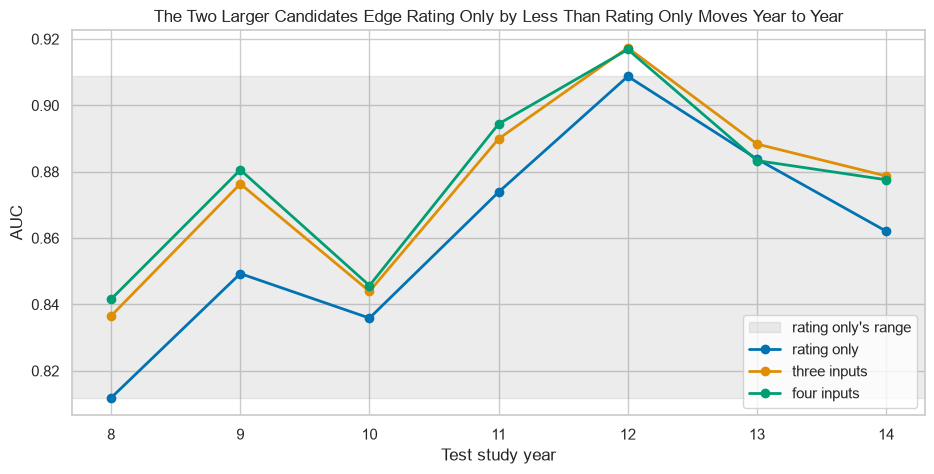

In [35]:
# the AUC by test year, rating only's range shaded
plt.figure(figsize=(11, 5))
plt.axhspan(fold_auc["rating only"].min(), fold_auc["rating only"].max(), color="gray", alpha=0.15, label="rating only's range")
for name in fold_auc.columns:
    plt.plot(fold_auc.index, fold_auc[name], marker="o", linewidth=2, label=name)
plt.xlabel("Test study year")
plt.ylabel("AUC")
plt.title("The Two Larger Candidates Edge Rating Only by Less Than Rating Only Moves Year to Year")
plt.legend(loc="lower right")
plt.show()

In [36]:
check("Q9 four inputs mean AUC", q9_four, "b569398977be", places=4)
check("Q9 rating only range", q9_range, "187255038b4f", places=4)
check("Q9 rating only counted over fitted", q9_ratio, "a75ad9b899b2", places=4)

Q9 four inputs mean AUC: correct
Q9 rating only range: correct
Q9 rating only counted over fitted: correct


![The range rule as a gate. Take the candidate with the highest mean AUC over test years 8 to 14. If its mean gain over rating only is larger than rating only's range across the years (its highest yearly AUC less its lowest), choose it; otherwise keep rating only. Below, the other reading, Exercise 1: choose it if its mean is higher and it is ahead in at least 4 of the 7 test years.](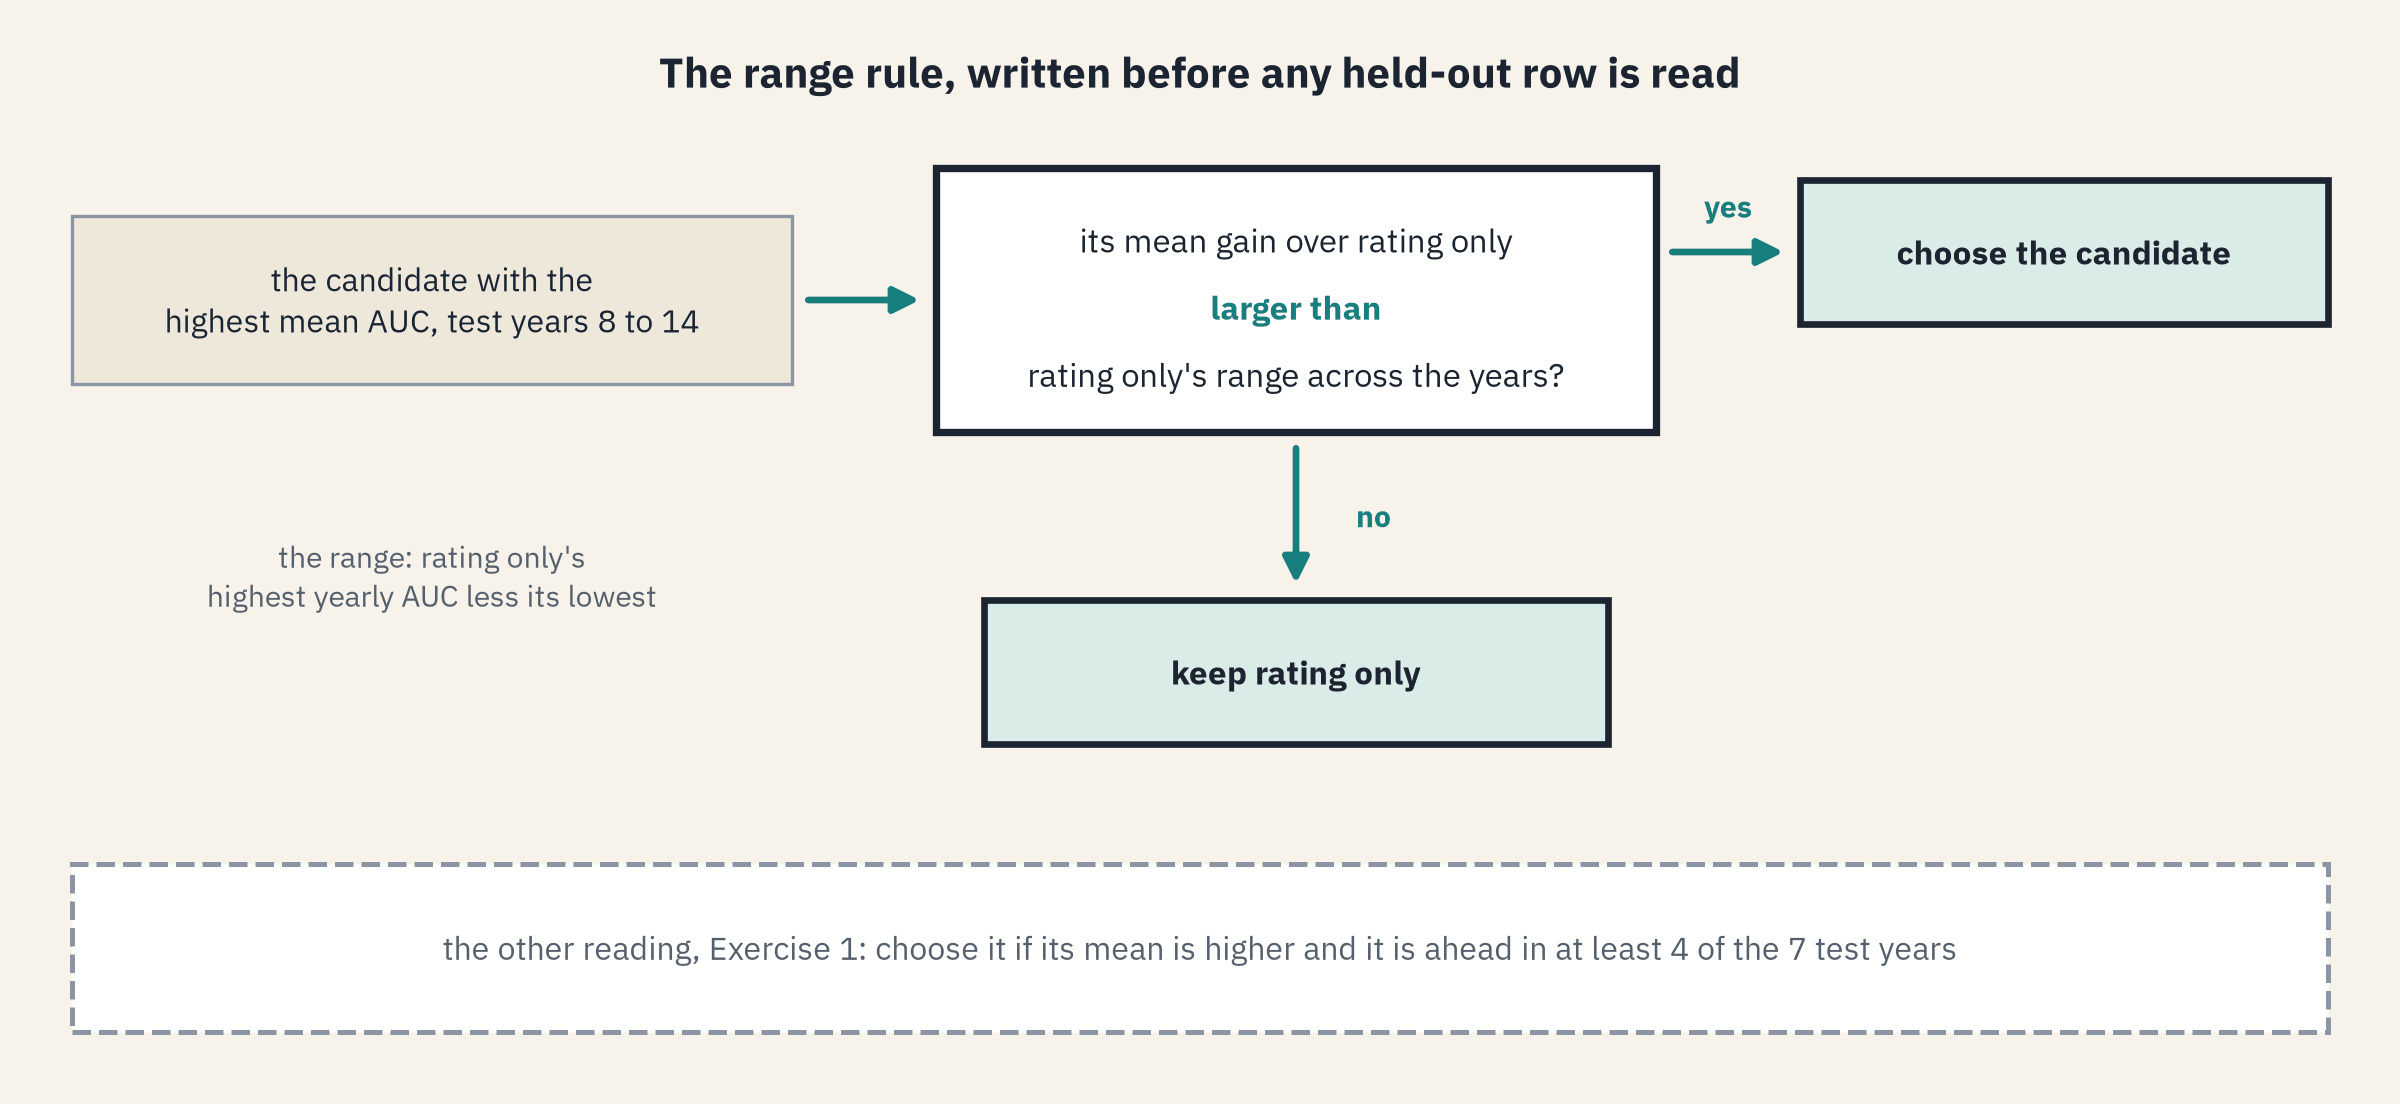)

## The Rule, Written First

Q. Write `choose_by_range(fold_auc, baseline)`, Course 5B's range rule on AUC, apply it with `"rating only"` as the baseline, and add the hazard entry to `choices`. Store the choice: `q10_choice`.

In [37]:
def choose_by_range(fold_auc, baseline):
    """The highest mean AUC if its mean gain over the baseline beats the baseline's range across the years, else the baseline."""
    best = fold_auc.mean().idxmax()
    gain = fold_auc[best].mean() - fold_auc[baseline].mean()
    return best if gain > fold_auc[baseline].max() - fold_auc[baseline].min() else baseline

q10_choice = choose_by_range(fold_auc, "rating only")
choices["hazard"] = {"rule": "the range rule", "baseline": "rating only", "chosen": q10_choice}
gain = fold_auc["four inputs"] - fold_auc["rating only"]
print("Chosen:", q10_choice, f"| four inputs' mean gain {gain.mean():.4f}, ahead in {(gain > 0).sum()} of 7")

Chosen: rating only | four inputs' mean gain 0.0163, ahead in 6 of 7


The four inputs led in 6 of 7 years by 0.0163 on average, far inside rating only's range of 0.0969; Exercise 1 writes the other rule.

In [38]:
check("Q10 the choice", q10_choice, "22030c58a316")

Q10 the choice: correct


## The Frozen Model

Q. The choice fitted on all the development firm-years is Q6's `pooled`: name it `frozen` and score `development["fitted"]`. Store the fitted sum (2 decimals) and the in-sample AUC (4 decimals): `q11_sum`, `q11_auc`.

In [39]:
# the range rule kept rating only, so the frozen model is Q6's pooled fit
frozen = pooled
development["fitted"] = frozen.predict(sm.add_constant(development[["rating_score"]]))
q11_sum, q11_auc = development["fitted"].sum(), roc_auc_score(development["default"], development["fitted"])
print(f"Constant {frozen.params['const']:.4f}, slope {frozen.params['rating_score']:.4f} | fitted sum {q11_sum:.2f} against {development['default'].sum()} | in-sample AUC {q11_auc:.4f}")

Constant -10.4489, slope 0.4967 | fitted sum 345.00 against 345 | in-sample AUC 0.8632


In [40]:
check("Q11 fitted sum", q11_sum, "ce0393563809", places=2)
check("Q11 in-sample AUC", q11_auc, "1a653c610fd8", places=4)

Q11 fitted sum: correct
Q11 in-sample AUC: correct


**The frozen hazard model and the book's default probabilities are one line, chosen before any held-out row.**

# The Anomaly Screen

## The Month With Planted Prints

Day 6's two published rules go into `choices` first, before the copy is made or a label read.

In [41]:
# Day 6's published rules: Iglewicz and Hoaglin's robust z above 3.5, and Tukey's outer fences
choices["screen"] = {"robust z above": 3.5, "outer fences k": 3}

# each trade's issuer, duration and month-end clean price from the book; then 12 planted prints, 9 moved 1.5 to 4 points, 3 slipped
trades = blotter.merge(book[["cusip", "issuer", "price", "duration"]].rename(columns={"price": "month_end_price"}), on="cusip", how="left")
rng = np.random.default_rng(SEED)
rows = rng.choice(len(blotter), 12, replace=False)
off_market, slipped = rows[:9], rows[9:]
prints = blotter.copy()
prints.loc[off_market, "price"] = (prints.loc[off_market, "price"] + rng.uniform(1.5, 4.0, 9) * rng.choice([-1.0, 1.0], 9)).round(3)
prints.loc[slipped, "price"] = (prints.loc[slipped, "price"] / 10).round(3)
planted = prints["price"] != blotter["price"]

In [42]:
# the 12 planted prints beside their true prices; the labels only score, and the copy is never written to disk
planted_table = trades.loc[planted, ["trade_id", "trade_date", "issuer", "duration", "price"]].rename(columns={"price": "true_price"})
planted_table["planted_price"] = prints.loc[planted, "price"]
planted_table["kind"] = np.where(planted_table.index.isin(slipped), "slipped decimal", "off-market")
planted_table

,trade_id,trade_date,issuer,duration,true_price,planted_price,kind
31,T0032,2026-09-02,Delvazor Paper,12.967,102.435,105.992,off-market
32,T0033,2026-09-02,Galvellix Paper,6.506,88.513,92.082,off-market
35,T0036,2026-09-02,Lorvane Systems,4.372,104.674,108.069,off-market
74,T0075,2026-09-08,Krilellix Networks,4.710,109.410,10.941,slipped decimal
158,T0159,2026-09-15,Zephiskan Resources,7.565,94.024,97.103,off-market
160,T0161,2026-09-15,Skelolvey Industrial,11.281,97.555,100.665,off-market
196,T0197,2026-09-16,Krilellix Networks,4.710,109.168,107.100,off-market
238,T0239,2026-09-21,Nevulex Health,4.846,103.617,106.503,off-market
258,T0259,2026-09-23,Feskebran Foods,5.183,99.437,9.944,slipped decimal
281,T0282,2026-09-24,Pellwick Paper,6.779,95.866,93.257,off-market


## Distance From the Month-End Price

Q. Measure Day 6's `distance` of each print in `prints` from its month-end price, in points per year of duration. Store its median and scaled MAD (4 decimals): `q12_median`, `q12_scaled_mad`.

In [43]:
# Day 6's distance, and its centre and robust yardstick
distance = (prints["price"] - trades["month_end_price"]) / trades["duration"]
q12_median = distance.median()
q12_scaled_mad = 1.4826 * (distance - q12_median).abs().median()
print(f"Median {q12_median:.4f} | scaled MAD {q12_scaled_mad:.4f} points per year of duration")

Median -0.0016 | scaled MAD 0.0854 points per year of duration


In [44]:
check("Q12 median distance", q12_median, "6e7f7c1832fa", places=4)
check("Q12 scaled MAD", q12_scaled_mad, "9e186d49605b", places=4)

Q12 median distance: correct
Q12 scaled MAD: correct


**Predict 2**

On Day 6's 14 planted prints the robust z at 3.5 found 12.

Q. How many of these 12 does it find? Write down a number.

## Day 6's Two Rules

Q. Repeat Day 6's `screen_performance`, and flag a robust z above 3.5 and the prints outside the outer fences, rows in `screens`. Store the robust rule's flags and planted found, and the fences' flags: `q13_flags`, `q13_found`, `q13_fences`.

Q. Draw each trade's robust z on a symlog axis by kind, and the two confusion matrices in `CELL_COLOURS`.

In [45]:
# Day 6's one row of scores for a screen
def screen_performance(flags, planted):
    """One row: the flags, the planted prints found, recall, precision and F1."""
    return pd.DataFrame({"Flags": [flags.sum()], "Planted Found": [(flags & planted).sum()],
                         "Recall": [recall_score(planted, flags)], "Precision": [precision_score(planted, flags)],
                         "F1": [f1_score(planted, flags)]})

In [46]:
# the robust z and the outer fences, each against the planted labels
robust_z = (distance - q12_median) / q12_scaled_mad
q1, q3 = distance.quantile([0.25, 0.75])
flags = {"robust z above 3.5": robust_z.abs() > 3.5, "outer fences": (distance < q1 - 3 * (q3 - q1)) | (distance > q3 + 3 * (q3 - q1))}
screens = pd.concat([screen_performance(f, planted) for f in flags.values()], ignore_index=True)
screens.index = list(flags)
q13_flags, q13_found, q13_fences = screens.iloc[0, 0], screens.iloc[0, 1], screens.iloc[1, 0]
screens.round(3)

,Flags,Planted Found,Recall,Precision,F1
robust z above 3.5,11,10,0.833,0.909,0.870
outer fences,7,7,0.583,1.000,0.737


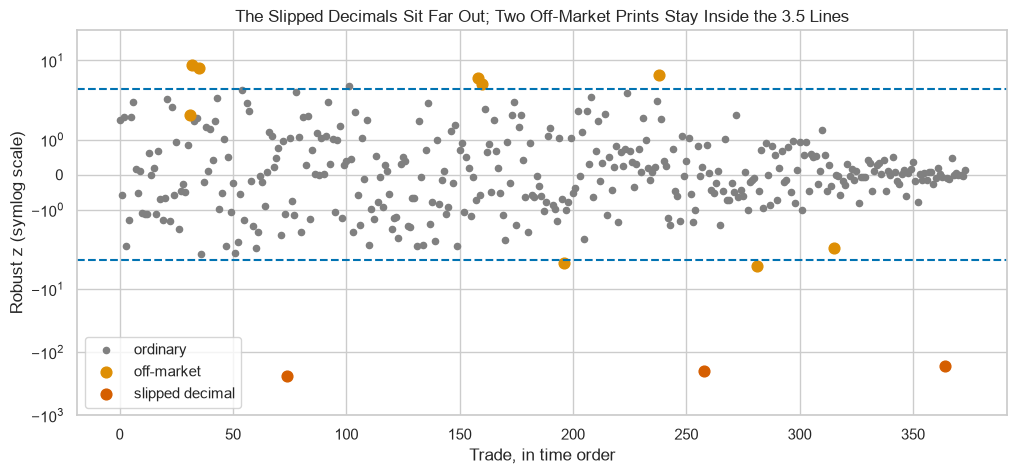

In [47]:
# each trade's robust z on a symlog axis, the 3.5 lines, the planted prints by kind
kind = np.where(prints.index.isin(slipped), "slipped decimal", np.where(planted, "off-market", "ordinary"))
plt.figure(figsize=(12, 5))
for name, colour in [("ordinary", "gray"), ("off-market", "C1"), ("slipped decimal", "C3")]:
    plt.scatter(prints.index[kind == name], robust_z[kind == name], s=20 if name == "ordinary" else 60, color=colour, label=name)
for line in [-3.5, 3.5]:
    plt.axhline(line, color="C0", linestyle="--")
plt.yscale("symlog")
plt.ylim(-1000, 30)
plt.xlabel("Trade, in time order")
plt.ylabel("Robust z (symlog scale)")
plt.title("The Slipped Decimals Sit Far Out; Two Off-Market Prints Stay Inside the 3.5 Lines")
plt.legend(loc="lower left")
plt.show()

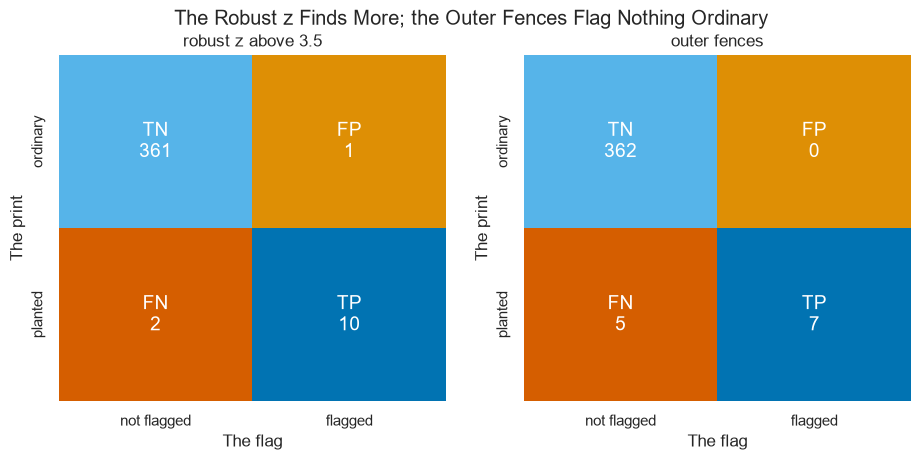

In [48]:
# the two confusion matrices: each cell in its own colour, with its name and its count
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, f) in zip(axes, flags.items()):
    tn, fp, fn, tp = confusion_matrix(planted, f).ravel()
    labels = [[f"TN\n{tn}", f"FP\n{fp}"], [f"FN\n{fn}", f"TP\n{tp}"]]
    sns.heatmap([[0, 1], [2, 3]], cmap=list(CELL_COLOURS.values()), annot=labels, fmt="", cbar=False, ax=ax, annot_kws={"size": 14},
                xticklabels=["not flagged", "flagged"], yticklabels=["ordinary", "planted"])
    ax.set(xlabel="The flag", ylabel="The print", title=name)
fig.suptitle("The Robust z Finds More; the Outer Fences Flag Nothing Ordinary")
plt.show()

In [49]:
# the planted prints the robust z misses, and the ordinary print it flags
missed = planted & ~flags["robust z above 3.5"]
print("Missed:", trades.loc[missed, "trade_id"].tolist(), "| points:", (prints.loc[missed, "price"] - trades.loc[missed, "price"]).round(2).tolist(),
      "| duration:", trades.loc[missed, "duration"].round(2).tolist(), "| robust z:", robust_z[missed].round(2).tolist())
print("Flagged, not planted:", trades.loc[flags["robust z above 3.5"] & ~planted, "trade_id"].tolist())

Missed: ['T0032', 'T0316'] | points: [3.56, -1.66] | duration: [12.97, 8.16] | robust z: [1.71, -2.25]
Flagged, not planted: ['T0102']


T0032 moved 3.56 points on a 12.97-year bond, a robust z of only 1.71.

In [50]:
check("Q13 robust z flags", q13_flags, "3e4e49f530d3", places=0)
check("Q13 robust z planted found", q13_found, "0eb999cde837", places=0)
check("Q13 outer fence flags", q13_fences, "345630f7c210", places=0)

Q13 robust z flags: correct
Q13 robust z planted found: correct
Q13 outer fence flags: correct


**Per year of duration a long bond's move can hide inside the yardstick; a flag is a print to check, nothing more.**

# Every Choice, Written First

## The Choices

Q. Repeat Day 8's three PSI functions, add the PSI settings and Day 9's bands to `choices`, and cut `EDGES` on development rows: every firm-year's `fitted` and three inputs, the entering firms' inputs (`"entrants leverage"`), and the 2 Yr and 10 Yr levels and whole-bp changes (`"2 Yr level"`, `"2 Yr change"`). Print `choices`, and store the edge sets: `q14_edges`.

In [51]:
# Day 8's three functions
def quantile_edges(reference, bins=10):
    """The reference's quantile edges for this many bins, equal edges merged."""
    return np.unique(np.quantile(reference, np.arange(1, bins) / bins))

def shares(sample, edges):
    """The sample's share in each bin, in bin order; the end bins are open."""
    return pd.cut(sample, np.concatenate([[-np.inf], edges, [np.inf]])).value_counts(normalize=True, sort=False)

def psi(reference, compared, edges, floor=0.0001):
    """PSI of the compared sample against the reference on fixed edges, each share floored first."""
    reference_share = shares(reference, edges).clip(lower=floor)
    compared_share = shares(compared, edges).clip(lower=floor)
    return ((compared_share - reference_share) * np.log(compared_share / reference_share)).sum()

In [52]:
# the PSI settings and Day 9's bands, then every edge from the development rows alone
choices["PSI"] = {"bins": 10, "edges": "development quantiles", "floor": 0.0001}
choices["bands"] = {"PSI": "green below 0.10, amber below 0.25", "AUC": "green within 0.03 of in-sample, amber within 0.07",
                    "count": "green inside the Poisson 95 percent range, amber inside the 99"}
entrants = development[development["years_since_entry"] == 1]
CHECKS, INPUTS = ["fitted", "rating_score", "leverage", "log_coverage"], ["rating_score", "leverage", "log_coverage"]
EDGES = {column: quantile_edges(development[column]) for column in CHECKS}
EDGES.update({f"entrants {column}": quantile_edges(entrants[column]) for column in INPUTS})
EDGES.update({f"{tenor} Yr level": quantile_edges(dev_curve[tenor]) for tenor in [2, 10]})
EDGES.update({f"{tenor} Yr change": quantile_edges(rate_moves[tenor].round(0)) for tenor in [2, 10]})
q14_edges = len(EDGES)

In [53]:
# every choice, printed before one held-out row is read
for piece, settings in choices.items():
    print(piece, settings)
print("Edge sets:", q14_edges, "| entering firms:", len(entrants))

VaR {'levels': [0.95, 0.99], 'fixed': 'the development days', 'rolling window': 500}
credit {'probabilities': 'the pooled fit', 'rho': 0.2, 'LGD': 'beta(6, 4)', 'scenarios': 20000}
hazard {'rule': 'the range rule', 'baseline': 'rating only', 'chosen': 'rating only'}
screen {'robust z above': 3.5, 'outer fences k': 3}
PSI {'bins': 10, 'edges': 'development quantiles', 'floor': 0.0001}
bands {'PSI': 'green below 0.10, amber below 0.25', 'AUC': 'green within 0.03 of in-sample, amber within 0.07', 'count': 'green inside the Poisson 95 percent range, amber inside the 99'}
Edge sets: 11 | entering firms: 3504


In [54]:
check("Q14 edge sets", q14_edges, "f6728e6a488a", places=0)

Q14 edge sets: correct


**Every choice was written where it was made, and all of them are printed here, before the held-out rows.**

# The Held-Out Years, Opened Once

## Reading Them Once

In [55]:
# the held-out rows, read once: the curve after the cut, and study years 15 to 20
held_curve = curve.loc[curve.index > CUT]
held_out = cohort[cohort["study_year"] > DEVELOPMENT_END].copy()
print(len(held_curve), "dates,", held_curve.index[0].date(), "to", held_curve.index[-1].date(), "|", len(held_out), "firm-years")

939 dates, 2023-01-03 to 2026-10-02 | 11112 firm-years


## The Book on 939 New Days

Q. Replay every day from the full files, the first held-out move from the 2022-12-30 levels, as `all_loss` (US$), and keep `held_loss` after the cut. Store the held-out sd (US$) and the worst day (`YYYY-MM-DD`): `q15_sd`, `q15_worst`.

In [56]:
# every day's moves from the full files, and each day's loss on today's book, a loss positive
all_rate_moves = (curve.diff() * 100).dropna()
all_spread_moves = (spreads.pct_change() * 100).dropna()
all_loss = -(-(all_rate_moves @ key_rate_dv01) - (all_spread_moves[dts_by_index.index] @ dts_by_index))
held_loss = all_loss[all_loss.index > CUT]
q15_sd, q15_worst = held_loss.std(), held_loss.idxmax().strftime("%Y-%m-%d")
print(f"{len(all_loss):,} days | held-out sd US${q15_sd:,.0f} against development US${loss.std():,.0f} | worst {q15_worst}, US${held_loss.max():,.0f}")

2,939 days | held-out sd US$1,923,524 against development US$1,726,060 | worst 2023-09-21, US$6,165,564


Had the daily moves of 2023-01-03 to 2026-10-02 repeated, with the book as of 2026-09-30 held fixed, the losses spread a little wider than over 2015 to 2022.

In [57]:
check("Q15 held-out sd", q15_sd, "7f04300f3bfd", places=0)
check("Q15 worst day", q15_worst, "c2096cb4a95c")

Q15 held-out sd: correct
Q15 worst day: correct


**Predict 3**

Inside development the rolling 99 percent VaR was beaten 28 times in 1,500 days, against 15 expected.

Q. How many times on the 939 held-out days, against about 9.4 expected? Write down a number.

## The VaR, Scored Once

Q. Count the held-out exceptions of the fixed development VaR and the rolling 500-day VaR, each at 95 and 99 percent, with `kupiec`, a table `backtest`. Store the fixed and rolling 99 exceptions and the rolling 95 p-value (4 decimals): `q16_fixed99`, `q16_rolling99`, `q16_rolling95_p`.

Q. Draw the held-out losses, both 99 percent VaRs and their exceptions.

In [58]:
# four VaRs on the held-out days: fixed on the development days, or rolling over the 500 days before each day
rows, names = [], []
for level in [0.95, 0.99]:
    rolling = all_loss.rolling(500).quantile(level).shift(1)[held_loss.index]
    for name, var in [("fixed", var_es(loss, level)[0]), ("rolling", rolling)]:
        x = (held_loss > var).sum()
        rows.append({"exceptions": x, "expected": len(held_loss) * (1 - level), "p-value": kupiec(x, len(held_loss), level)[1]})
        names.append(f"{name} {100 * level:.0f} percent")
backtest = pd.DataFrame(rows, index=names)
q16_fixed99, q16_rolling99, q16_rolling95_p = backtest.loc["fixed 99 percent", "exceptions"], backtest.loc["rolling 99 percent", "exceptions"], backtest.loc["rolling 95 percent", "p-value"]
backtest.round(4)

,exceptions,expected,p-value
fixed 95 percent,58,46.95,0.1099
rolling 95 percent,26,46.95,0.0006
fixed 99 percent,8,9.39,0.6399
rolling 99 percent,7,9.39,0.4117


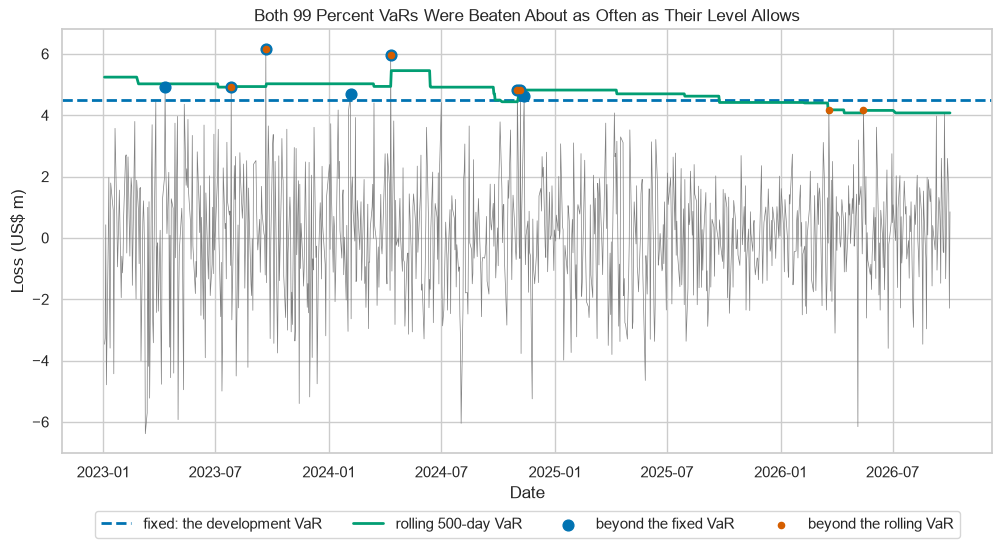

In [59]:
# the held-out losses, the fixed and the rolling 99 percent VaR, and the days beyond each
rolling_99 = all_loss.rolling(500).quantile(0.99).shift(1)[held_loss.index]
fixed_99 = var_es(loss, 0.99)[0]
plt.figure(figsize=(12, 5.5))
plt.plot(held_loss.index, held_loss / 1e6, linewidth=0.5, color="gray")
plt.axhline(fixed_99 / 1e6, color="C0", linestyle="--", linewidth=2, label="fixed: the development VaR")
plt.plot(rolling_99.index, rolling_99 / 1e6, color="C2", linewidth=2, label="rolling 500-day VaR")
plt.scatter(held_loss.index[held_loss > fixed_99], held_loss[held_loss > fixed_99] / 1e6, s=60, color="C0", zorder=3, label="beyond the fixed VaR")
plt.scatter(held_loss.index[held_loss > rolling_99], held_loss[held_loss > rolling_99] / 1e6, s=20, color="C3", zorder=4, label="beyond the rolling VaR")
plt.xlabel("Date")
plt.ylabel("Loss (US$ m)")
plt.title("Both 99 Percent VaRs Were Beaten About as Often as Their Level Allows")
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncols=4)
plt.show()

At 95 percent the rolling VaR was beaten 26 times against 46.95; Kupiec rejects at 0.0006.

The rolling 99 percent VaR opened at US$5.24m, its window holding 2021 and 2022, and closed at US$4.07m.

In [60]:
check("Q16 fixed 99 exceptions", q16_fixed99, "1aceb34e8abc", places=0)
check("Q16 rolling 99 exceptions", q16_rolling99, "756c533be912", places=0)
check("Q16 rolling 95 p-value", q16_rolling95_p, "e8454946c4ce", places=4)

Q16 fixed 99 exceptions: correct
Q16 rolling 99 exceptions: correct
Q16 rolling 95 p-value: correct


## Where Each Day Fell in Its Window

A **percentile-rank histogram** (a PIT histogram) ranks each day's loss in the 501 days to it, with Course 3's `.rolling(501).rank(pct=True, method="max")`, in 20 equal bins.
Windows like the days they score give flat counts.
`stats.binom.interval(0.95, n, 0.05)` holds the middle 95 percent of one bin's count, as Day 9's `stats.poisson.interval` held a year's defaults.

Q. Count the development ranks from 2017-01-03 and the held-out ranks. Store the held-out highest bin and the band's ends for 939 days: `q17_high_bin`, `q17_low`, `q17_high`.

Q. Draw both, each with its expected count and band.

In [61]:
# each day's share of the 501 days to it at or below its loss, then 20 equal bins for each period
rank = all_loss.rolling(501).rank(pct=True, method="max")
periods = {"development, from 2017-01-03": rank.loc[:CUT].dropna(), "held-out": rank[held_loss.index]}
bin_edges = np.linspace(0, 1, 21)
for name, ranks in periods.items():
    counts = np.histogram(ranks, bin_edges)[0]
    low, high = stats.binom.interval(0.95, len(ranks), 0.05)
    print(f"{name}: {len(ranks)} days | highest bin {counts[-1]}, lowest {counts[0]} | expected {len(ranks) / 20:.2f}, band {low:.0f} to {high:.0f}")
q17_high_bin = np.histogram(periods["held-out"], bin_edges)[0][-1]
q17_low, q17_high = stats.binom.interval(0.95, len(periods["held-out"]), 0.05)

development, from 2017-01-03: 1500 days | highest bin 103, lowest 91 | expected 75.00, band 59 to 92
held-out: 939 days | highest bin 27, lowest 40 | expected 46.95, band 34 to 60


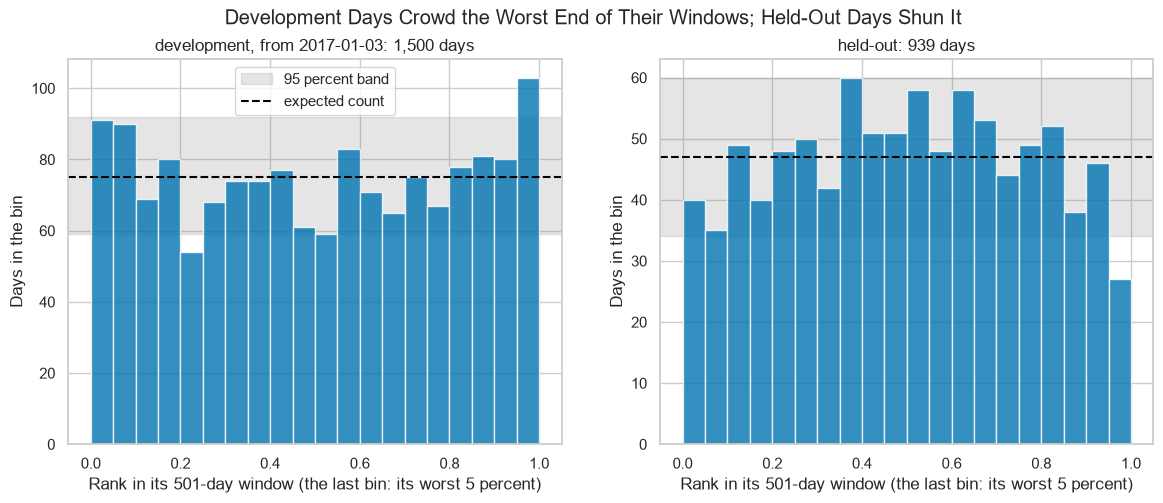

In [62]:
# the two percentile-rank histograms, each with its flat expected count and its band
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (name, ranks) in zip(axes, periods.items()):
    low, high = stats.binom.interval(0.95, len(ranks), 0.05)
    ax.axhspan(low, high, color="gray", alpha=0.2, label="95 percent band")
    ax.hist(ranks, bins=bin_edges, color="C0", alpha=0.8, edgecolor="white")
    ax.axhline(len(ranks) / 20, color="black", linestyle="--", label="expected count")
    ax.set(title=f"{name}: {len(ranks):,} days", xlabel="Rank in its 501-day window (the last bin: its worst 5 percent)", ylabel="Days in the bin")
axes[0].legend(loc="upper center")
fig.suptitle("Development Days Crowd the Worst End of Their Windows; Held-Out Days Shun It")
plt.show()

The highest bin holds 103 against a band of 59 to 92 inside development, and 27 against 34 to 60 on the held-out days.

In [63]:
check("Q17 held-out days in the highest bin", q17_high_bin, "4804814783bb", places=0)
check("Q17 band low", q17_low, "2a057627eae4", places=0)
check("Q17 band high", q17_high, "1269cd1cf37b", places=0)

Q17 held-out days in the highest bin: correct
Q17 band low: correct
Q17 band high: correct


**At 99 percent the VaR was beaten about as often as its level says; at 95 the rolling window held a busier past than the held-out days.**

# Study Years 15 to 20, Scored Once

**Predict 4**

Walked forward over test years 8 to 14, rating only counted 0.9137 of its fitted defaults.

Q. Frozen on study years 1 to 14, what is its counted over fitted on 15 to 20 pooled? Write down a number.

## The Frozen Model, Year by Year

Q. Score `held_out` with `frozen`, add Day 5's features, and keep each year's counted, fitted, ratio and AUC in `held_years`. Store the pooled counted over fitted and AUC (4 decimals): `q18_ratio`, `q18_auc`.

Q. Draw Day 9's count ladder for study years 1 to 20.

In [64]:
# the frozen model's default probability for every held-out firm-year, and Day 5's two features
held_out["fitted"] = frozen.predict(sm.add_constant(held_out[["rating_score"]]))
held_out["log_coverage"] = np.log(held_out["coverage"])
held_out["early_years"] = held_out["years_since_entry"].between(2, 4).astype(int)

# each held-out study year: counted, the model's count, their ratio and the AUC
held_years = held_out.groupby("study_year").agg(counted=("default", "sum"), fitted=("fitted", "sum"))
held_years["ratio"] = held_years["counted"] / held_years["fitted"]
held_years["AUC"] = [roc_auc_score(rows["default"], rows["fitted"]) for _, rows in held_out.groupby("study_year")]
q18_ratio, q18_auc = held_out["default"].sum() / held_out["fitted"].sum(), roc_auc_score(held_out["default"], held_out["fitted"])
print(f"Pooled 15 to 20: {held_out['default'].sum()} counted against {held_out['fitted'].sum():.2f} fitted, {q18_ratio:.4f} | AUC {q18_auc:.4f}")
held_years.round(4)

Pooled 15 to 20: 346 counted against 253.10 fitted, 1.3671 | AUC 0.8521


,counted,fitted,ratio,AUC
study_year,,,,
15,84,51.8596,1.6198,0.8606
16,67,54.9263,1.2198,0.8591
17,67,46.0055,1.4563,0.8410
18,44,38.4140,1.1454,0.8357
19,59,33.5273,1.7598,0.8415
20,25,28.3655,0.8814,0.8833


In [65]:
# Day 3's measure: each year's gap in its independent sd, squared and averaged; about the frozen count, then the held-out level
sd = held_out.groupby("study_year")["fitted"].apply(lambda p: np.sqrt((p * (1 - p)).sum()))
gap = (held_years["counted"] - held_years["fitted"]) / sd
gap_level = (held_years["counted"] - q18_ratio * held_years["fitted"]) / sd
print(f"Average squared gap: {(gap ** 2).mean():.2f} about the frozen count | {(gap_level ** 2).mean():.2f} about the held-out level")

Average squared gap: 9.56 about the frozen count | 3.36 about the held-out level


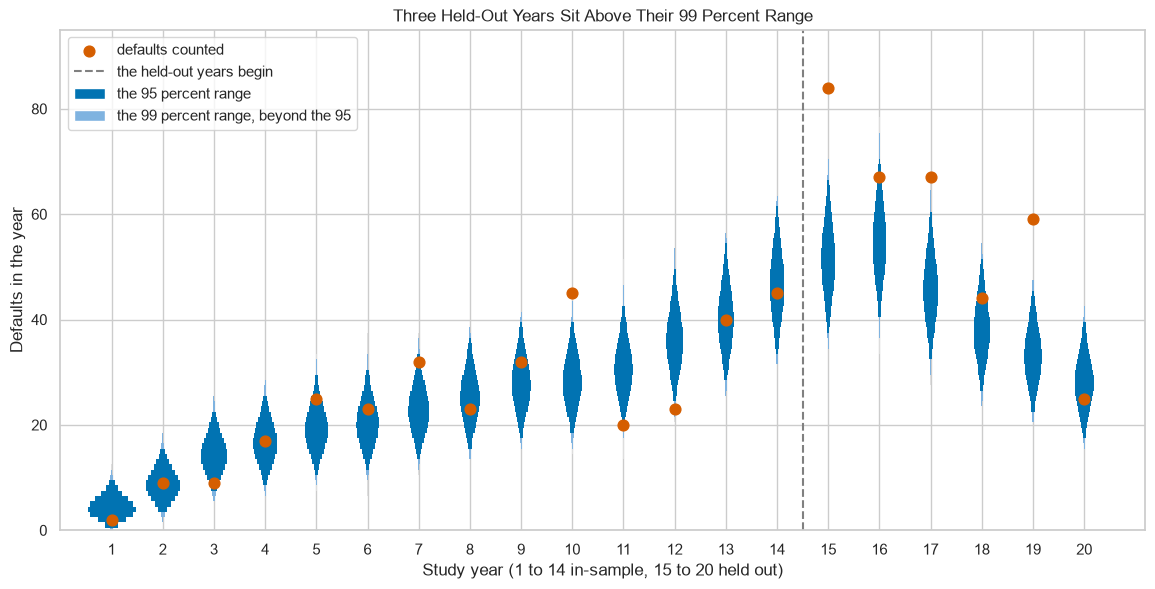

In [66]:
# the count ladder, study years 1 to 20: each year's Poisson chances drawn sideways, the counted defaults a dot
years = pd.concat([development, held_out]).groupby("study_year").agg(counted=("default", "sum"), fitted=("fitted", "sum"))
counts = np.arange(0, 100)
widest = stats.poisson.pmf(counts, years["fitted"].min()).max()
fig, ax = plt.subplots(figsize=(14, 6.5))
for year, row in years.iterrows():
    half = 0.47 * stats.poisson.pmf(counts, row["fitted"]) / widest
    low_95, high_95 = stats.poisson.interval(0.95, row["fitted"])
    low_99, high_99 = stats.poisson.interval(0.99, row["fitted"])
    shade = np.where((counts >= low_95) & (counts <= high_95), "C0", np.where((counts >= low_99) & (counts <= high_99), "#7fb3e0", "#dddddd"))
    ax.barh(counts, 2 * half, left=year - half, height=1, color=shade, linewidth=0)
for colour, name in [("C0", "the 95 percent range"), ("#7fb3e0", "the 99 percent range, beyond the 95")]:
    ax.barh(-10, 0, color=colour, label=name)
ax.scatter(years.index, years["counted"], color="C3", s=60, zorder=3, label="defaults counted")
ax.axvline(DEVELOPMENT_END + 0.5, color="gray", linestyle="--", label="the held-out years begin")
ax.set(xticks=years.index, ylim=(0, 95), xlabel="Study year (1 to 14 in-sample, 15 to 20 held out)", ylabel="Defaults in the year", title="Three Held-Out Years Sit Above Their 99 Percent Range")
ax.legend(loc="upper left")
plt.show()

Day 3's average squared gap, 2.17 in development, reads 9.56: the level's miss and the years' clustering together.

About the held-out level it still reads 3.36: the Poisson range allows for no clustering, so it is narrower than the years' own spread.

In [67]:
check("Q18 pooled counted over fitted", q18_ratio, "7d5fb75efe95", places=4)
check("Q18 pooled AUC", q18_auc, "2f1a63e0bac4", places=4)

Q18 pooled counted over fitted: correct
Q18 pooled AUC: correct


## The Report Each Year

Q. Repeat Day 9's `monitoring_report` with `reference = development` (in-sample AUC), on each held-out year and the six pooled, reading `EDGES`. Store the years with the count red: `q19_red`.

Q. Draw Day 9's status grid.

In [68]:
def monitoring_report(reference, current, edges):
    """Four PSIs, the AUC and counted over fitted of current against reference, each with its status."""
    values = {f"PSI {column}": psi(reference[column], current[column], edges[column]) for column in CHECKS}
    status = {name: "green" if value < 0.10 else "amber" if value < 0.25 else "red" for name, value in values.items()}
    in_sample = roc_auc_score(reference["default"], reference["fitted"])
    values["AUC"] = roc_auc_score(current["default"], current["fitted"])
    status["AUC"] = "green" if values["AUC"] >= in_sample - 0.03 else "amber" if values["AUC"] >= in_sample - 0.07 else "red"
    counted, fitted_count = current["default"].sum(), current["fitted"].sum()
    low_95, high_95 = stats.poisson.interval(0.95, fitted_count)
    low_99, high_99 = stats.poisson.interval(0.99, fitted_count)
    values["Counted over fitted"] = counted / fitted_count
    status["Counted over fitted"] = "green" if low_95 <= counted <= high_95 else "amber" if low_99 <= counted <= high_99 else "red"
    return pd.DataFrame({"Value": values, "Status": status})

# the three status colours, from the course palette
STATUS_COLOURS = {"green": "#029E73", "amber": "#ECE133", "red": "#D55E00"}

In [69]:
# each held-out year, then the six pooled, against the development rows
reports = {year: monitoring_report(development, rows, EDGES) for year, rows in held_out.groupby("study_year")}
reports["pooled"] = monitoring_report(development, held_out, EDGES)
values = pd.DataFrame({year: report["Value"] for year, report in reports.items()})
statuses = pd.DataFrame({year: report["Status"] for year, report in reports.items()})
q19_red = (statuses.loc["Counted over fitted", list(range(15, 21))] == "red").sum()
print("Count red in:", [year for year in range(15, 21) if statuses.loc["Counted over fitted", year] == "red"], "| pooled:", statuses.loc["Counted over fitted", "pooled"])
print("Lowest AUC:", round(values.loc["AUC"].min(), 4), "| its green line:", round(q11_auc - 0.03, 4))

Count red in: [15, 17, 19] | pooled: red
Lowest AUC: 0.8357 | its green line: 0.8332


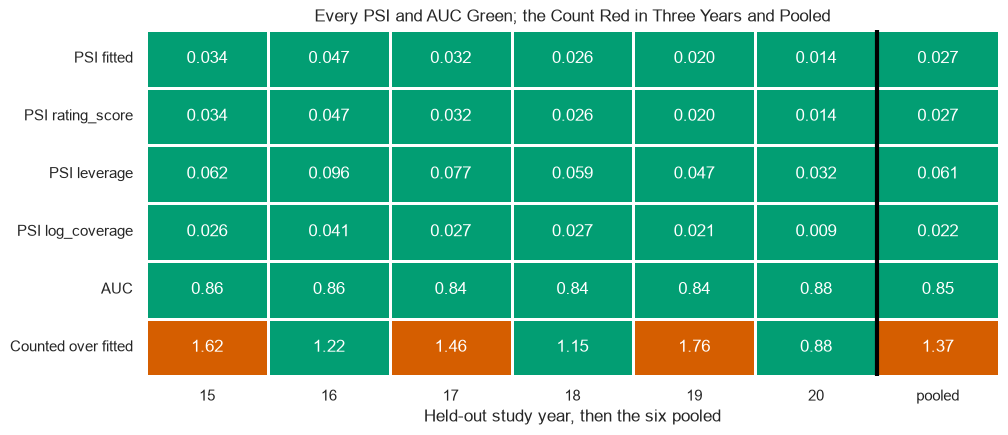

In [70]:
# the status grid: colour by status, the value written in
codes = (statuses == "amber") * 1 + (statuses == "red") * 2
labels = [[f"{v:.2f}" if name in ["AUC", "Counted over fitted"] else f"{v:.3f}" for v in values.loc[name]] for name in values.index]
fig, ax = plt.subplots(figsize=(11, 4.5))
sns.heatmap(codes, cmap=list(STATUS_COLOURS.values()), vmin=0, vmax=2, annot=labels, fmt="", cbar=False, linewidths=1, linecolor="white", ax=ax)
ax.axvline(6, color="black", linewidth=3)
ax.set(xlabel="Held-out study year, then the six pooled", ylabel="", title="Every PSI and AUC Green; the Count Red in Three Years and Pooled")
plt.show()

The fitted chance is a function of rating alone, so its PSI equals rating's.

In [71]:
check("Q19 years with the count red", q19_red, "13dd6b6aacaf", places=0)

Q19 years with the count red: correct


## Defaults by Rating

Q. Count defaults against fitted by bucket, AAA to CCC, as `by_bucket`. Store the counted default rate of study years 15 to 20 (percent a year, 2 decimals) and B's counted over fitted (4 decimals): `q20_rate`, `q20_b`.

In [72]:
# each held-out firm-year's bucket, then counted against fitted by bucket
held_out = held_out.merge(ratings[["rating", "bucket"]], on="rating")
by_bucket = held_out.groupby("bucket").agg(firm_years=("default", "size"), counted=("default", "sum"), fitted=("fitted", "sum")).loc[["AAA", "AA", "A", "BBB", "BB", "B", "CCC"]]
by_bucket["ratio"] = by_bucket["counted"] / by_bucket["fitted"]
q20_rate, q20_b = 100 * held_out["default"].mean(), by_bucket.loc["B", "ratio"]
print(f"Counted default rate, study years 15 to 20: {q20_rate:.2f} percent a year")
by_bucket.round(3)

Counted default rate, study years 15 to 20: 3.11 percent a year


,firm_years,counted,fitted,ratio
bucket,,,,
AAA,59,0,0.003,0.000
AA,662,0,0.110,0.000
A,1441,0,0.947,0.000
BBB,2703,15,7.889,1.901
BB,3206,45,37.599,1.197
B,2387,167,113.924,1.466
CCC,654,119,92.625,1.285


AAA to A counted no default against fitted counts below 1; BBB ran 1.90 times on 15 defaults.

In [73]:
check("Q20 counted default rate", q20_rate, "869d84876cce", places=2)
check("Q20 B counted over fitted", q20_b, "a0c4fbf36df8", places=4)

Q20 counted default rate: correct
Q20 B counted over fitted: correct


**Predict 5**

At the development level one run of 20,000 put the 99.9 percent credit loss at US$36.2m.

Q. With every bond's probability scaled by the pooled counted over fitted of study years 15 to 20, what is it? Write down a number in US$ m.

## The Book's Credit Loss at the Counted Level

Q. Scale every bond's probability by `q18_ratio`, an input for the comparison, and run `credit_losses` once from `default_rng(SEED)` as `counted_losses`, then ten spawned times. Store the 99.9 percent VaR (US$) and its ratio to Q7's (3 decimals): `q21_var999`, `q21_times`.

Q. Draw both quantile dot plots on one axis.

In [74]:
# the book's probabilities scaled by the cohort's held-out counted over fitted, then one run of 20,000
scaled = book["default_prob"].to_numpy() * q18_ratio
counted_losses = credit_losses(scaled, 20_000, np.random.default_rng(SEED))
q21_var999 = var_es(counted_losses, 0.999)[0]
q21_times = q21_var999 / q7_var999
print(f"Largest probability {scaled.max():.4f} | expected loss US${(scaled * LGD_MEAN * mv).sum():,.0f} | mean US${counted_losses.mean():,.0f} (standard error US${counted_losses.std(ddof=1) / np.sqrt(20_000):,.0f})")

Largest probability 0.2479 | expected loss US$4,760,661 | mean US$4,717,461 (standard error US$39,543)


In [75]:
# the 99 and 99.9 percent VaR beside ten spawned runs of 20,000, in US$ m, and their ratios to Q7's
counted_runs = pd.DataFrame([{level: var_es(credit_losses(scaled, 20_000, child), level)[0] for level in [0.99, 0.999]}
                             for child in np.random.default_rng(SEED).spawn(10)]) / 1e6
for level, name in [(0.99, "99"), (0.999, "99.9")]:
    print(f"{name} percent: US${var_es(counted_losses, level)[0] / 1e6:.2f}m, {var_es(counted_losses, level)[0] / var_es(losses, level)[0]:.3f} times Q7's | ten runs {counted_runs[level].min():.2f} to {counted_runs[level].max():.2f}, sd {counted_runs[level].std():.2f}")

99 percent: US$25.86m, 1.223 times Q7's | ten runs 25.27 to 26.08, sd 0.28
99.9 percent: US$41.91m, 1.158 times Q7's | ten runs 39.96 to 43.40, sd 1.35


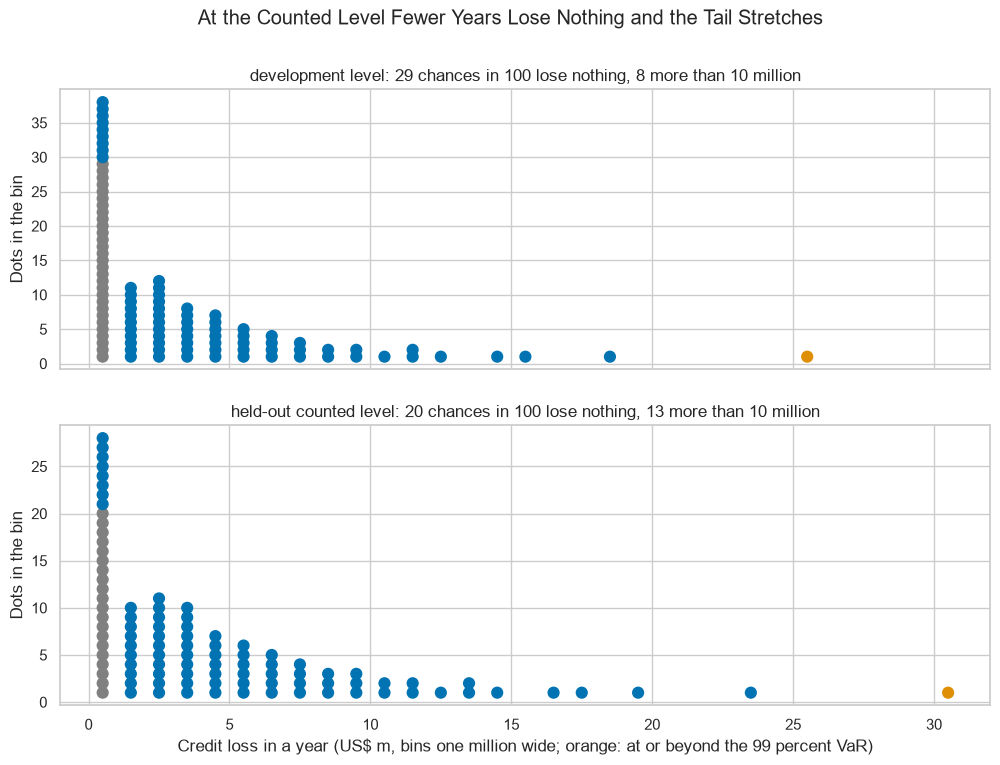

In [76]:
# the two quantile dot plots on one value axis, a zero loss grey
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
for ax, (name, sample) in zip(axes, [("development level", losses), ("held-out counted level", counted_losses)]):
    dots = np.quantile(sample, (np.arange(1, 101) - 0.5) / 100) / 1e6
    bins = np.floor(dots)
    height = pd.Series(bins).groupby(bins).cumcount().to_numpy() + 1
    colour = np.where(dots >= var_es(sample, 0.99)[0] / 1e6, "C1", np.where(dots == 0, "gray", "C0"))
    ax.scatter(bins + 0.5, height, s=60, color=colour)
    ax.set(ylabel="Dots in the bin", title=f"{name}: {(dots == 0).sum()} chances in 100 lose nothing, {(dots > 10).sum()} more than 10 million")
axes[1].set_xlabel("Credit loss in a year (US$ m, bins one million wide; orange: at or beyond the 99 percent VaR)")
fig.suptitle("At the Counted Level Fewer Years Lose Nothing and the Tail Stretches")
plt.show()

One multiplier for every rating, where Q20's buckets ran from 1.20 to 1.90, shows the size of the level's miss, not each rating's.

In [77]:
check("Q21 VaR 99.9 at the counted level", q21_var999, "83762ef7ad77", places=0)
check("Q21 ratio to the development run", q21_times, "1a4c1e154021", places=3)

Q21 VaR 99.9 at the counted level: correct
Q21 ratio to the development run: correct


**The defaults counted ran above the model's count while its order held; at that level the 99.9 percent loss grew by about a sixth.**

# The Two Periods, Compared by PSI

**Predict 6**

Inside development Day 8 found the 10 Yr level's PSI at 1.72 and its daily change's at 0.041.

Q. Held-out against development, on the development edges: the 10 Yr level's PSI, and its change's? Write down two numbers.

## The PSI Table

Q. With `psi` and `EDGES`, compute held-out against development for all eleven entries, in order, as `psi_table`. Store the 10 Yr level's, the 10 Yr change's and the entering firms' leverage's (4 decimals): `q22_level`, `q22_change`, `q22_entrants`.

Q. Draw `psi_table` as dots on a log axis, Day 8's two Yurdakul ends dotted.

In [78]:
# each entry's development sample and held-out sample, in EDGES' order
held_entrants = held_out[held_out["years_since_entry"] == 1]
held_moves = all_rate_moves.loc[held_loss.index]
samples = {column: (development[column], held_out[column]) for column in CHECKS}
samples.update({f"entrants {column}": (entrants[column], held_entrants[column]) for column in INPUTS})
samples.update({f"{tenor} Yr level": (dev_curve[tenor], held_curve[tenor]) for tenor in [2, 10]})
samples.update({f"{tenor} Yr change": (rate_moves[tenor].round(0), held_moves[tenor].round(0)) for tenor in [2, 10]})
psi_table = pd.Series({name: psi(reference, compared, EDGES[name]) for name, (reference, compared) in samples.items()})
q22_level, q22_change, q22_entrants = psi_table["10 Yr level"], psi_table["10 Yr change"], psi_table["entrants leverage"]
print("Entering firms:", len(entrants), "against", len(held_entrants), "| 2 Yr change bins:", len(EDGES["2 Yr change"]) + 1)
psi_table.round(4)

Entering firms: 3504 against 496 | 2 Yr change bins: 9


fitted                   0.0271
rating_score             0.0271
leverage                 0.0613
log_coverage             0.0219
entrants rating_score    0.5962
entrants leverage        0.8056
entrants log_coverage    0.2920
2 Yr level               8.2954
10 Yr level              8.3331
2 Yr change              0.3565
10 Yr change             0.0682
dtype: float64

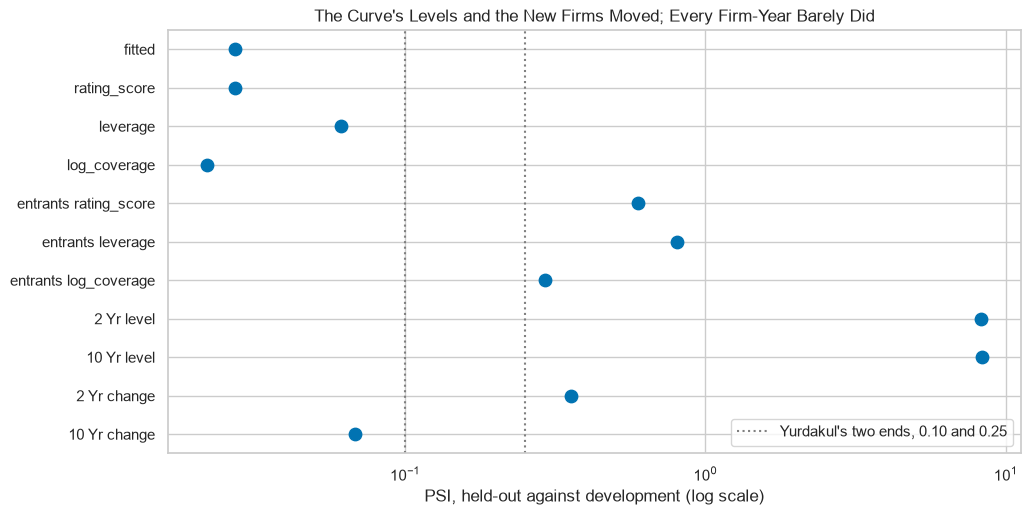

In [79]:
# the PSIs as dots on a log axis, Yurdakul's two ends dotted
plt.figure(figsize=(11, 5.5))
plt.scatter(psi_table, psi_table.index, s=80, color="C0", zorder=3)
plt.axvline(0.10, color="gray", linestyle=":", label="Yurdakul's two ends, 0.10 and 0.25")
plt.axvline(0.25, color="gray", linestyle=":")
plt.xscale("log")
plt.gca().invert_yaxis()
plt.xlabel("PSI, held-out against development (log scale)")
plt.title("The Curve's Levels and the New Firms Moved; Every Firm-Year Barely Did")
plt.legend(loc="lower right")
plt.show()

The dotted lines are the two ends Day 8 quoted from Yurdakul's abstract (https://scholarworks.wmich.edu/dissertations/3208/): below 0.10 "little shift", 0.25 "significant shift, action required".

In [80]:
check("Q22 10 Yr level PSI", q22_level, "855d76e20d56", places=4)
check("Q22 10 Yr change PSI", q22_change, "928c15ce6d65", places=4)
check("Q22 entering firms' leverage PSI", q22_entrants, "649f05c820a1", places=4)

Q22 10 Yr level PSI: correct
Q22 10 Yr change PSI: correct
Q22 entering firms' leverage PSI: correct


## A Level Outside Its Ruler

Q. Read the 10 Yr level's held-out shares on its edges, the share above the development's highest level, and its PSI at floors 0.0001, 0.001 and 0.01. Store the share (3 decimals) and the PSI at 0.01 (2 decimals): `q23_above`, `q23_floor`.

Q. Redraw the candlesticks with all 48 quarters.

In [81]:
# the 10 Yr's held-out shares in its development bins, and the share above the development's highest level
print("Held-out shares:", shares(held_curve[10], EDGES["10 Yr level"]).round(3).tolist())
q23_above = (held_curve[10] > dev_curve[10].max()).mean()

# the same PSI at three floors: with one bin holding every day, the floor sets the number
by_floor = {floor: round(float(psi(dev_curve[10], held_curve[10], EDGES["10 Yr level"], floor)), 2) for floor in [0.0001, 0.001, 0.01]}
q23_floor = by_floor[0.01]
print(f"Above {dev_curve[10].max()} percent: {q23_above:.3f} of held-out days | PSI by floor:", by_floor)
print("2 Yr changes of 0 bp:", round((rate_moves[2].round(0) == 0).mean(), 3), "of development days,", round((held_moves[2].round(0) == 0).mean(), 3), "of held-out days")

Held-out shares: [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0]
Above 4.25 percent: 0.501 of held-out days | PSI by floor: {0.0001: 8.33, 0.001: 6.22, 0.01: 3.98}
2 Yr changes of 0 bp: 0.208 of development days, 0.106 of held-out days


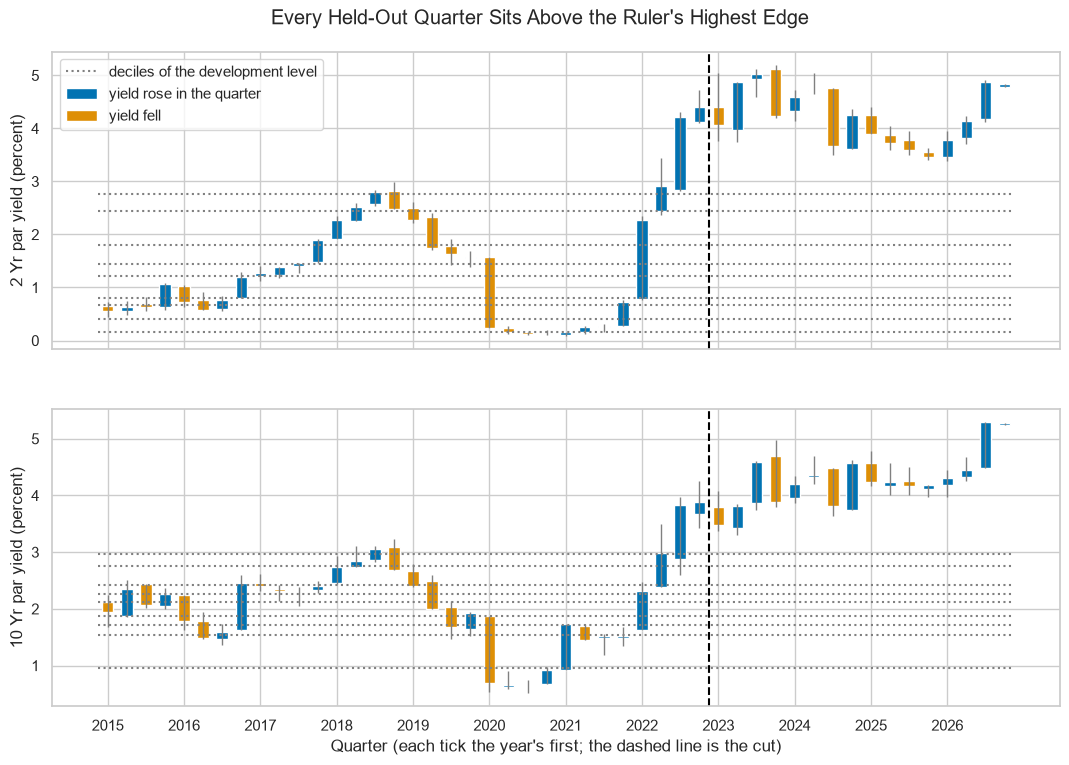

In [82]:
# all 48 quarters on the development ruler, the cut dashed
all_quarters = curve.index.to_period("Q").nunique()
fig, axes = plt.subplots(2, 1, figsize=(13, 8.5), sharex=True)
for ax, tenor in zip(axes, [2, 10]):
    q = curve[tenor].groupby(curve.index.to_period("Q")).agg(["first", "max", "min", "last"])
    x = np.arange(len(q))
    ax.vlines(x, q["min"], q["max"], color="gray", linewidth=1)
    for rose, colour, label in [(q["last"] >= q["first"], "C0", "yield rose in the quarter"), (q["last"] < q["first"], "C1", "yield fell")]:
        ax.bar(x[rose], (q["last"] - q["first"])[rose], bottom=q["first"][rose], width=0.6, color=colour, label=label)
    ax.hlines(ruler[tenor], -0.5, len(x) - 0.5, color="gray", linestyle=":", label="deciles of the development level")
    ax.axvline(len(quarters[tenor]) - 0.5, color="black", linestyle="--")
    ax.set(ylabel=f"{tenor} Yr par yield (percent)")
axes[0].legend(loc="upper left")
axes[1].set_xticks(np.arange(0, all_quarters, 4), range(2015, 2027))
axes[1].set_xlabel("Quarter (each tick the year's first; the dashed line is the cut)")
fig.suptitle("Every Held-Out Quarter Sits Above the Ruler's Highest Edge", y=0.93)
plt.show()

With nine bins empty the floor sets the 10 Yr level's PSI, from 8.33 at 0.0001 to 3.98 at 0.01.

The 10 Yr's moves, 37.7 percent of the book's DV01 (Day 2), shifted only 0.068.

The 2 Yr's rounded change was 0 bp on 20.8 percent of development days and 10.6 percent of held-out days; the file does not record why.

In [83]:
check("Q23 share above the development's highest", q23_above, "b830f7de1e25", places=3)
check("Q23 PSI at floor 0.01", q23_floor, "703e401517dc", places=2)

Q23 share above the development's highest: correct
Q23 PSI at floor 0.01: correct


**The levels left their ruler; the moves the VaR reads mostly did not, and the new firms moved while every firm-year stayed green.**

# Insights and Conclusion

## What the Models Show, and Where They Fail

Q. Write `description`: what held on the held-out rows, where each model failed, and what was not tested.

In [84]:
# a few sentences about the rows in these files
description = ("Had the moves of 2023 to 2026 repeated on the book held fixed, the 99 percent VaR was beaten about as often as its level says, 8 and 7 times in 939 days. "
               "At 95 percent the rolling VaR was beaten 26 times against 46.95, its window holding a busier past, and two of the seven gaps between the fixed VaR's exceptions were three trading days. "
               "The range rule kept rating only; frozen, it ranked study years 15 to 20 at AUCs of 0.84 to 0.88, while the defaults counted were 1.37 times its count, in years that clustered. "
               "Every firm-year's inputs stayed green while the entering firms' leverage moved by a PSI of 0.81, and the curve's levels left their ruler, so their PSI was set by the floor. "
               "The screen missed a 3.56-point print on a long bond. "
               "Not tested: another cut, another book date, convexity, a cost for each check.")
print(description)

Had the moves of 2023 to 2026 repeated on the book held fixed, the 99 percent VaR was beaten about as often as its level says, 8 and 7 times in 939 days. At 95 percent the rolling VaR was beaten 26 times against 46.95, its window holding a busier past, and two of the seven gaps between the fixed VaR's exceptions were three trading days. The range rule kept rating only; frozen, it ranked study years 15 to 20 at AUCs of 0.84 to 0.88, while the defaults counted were 1.37 times its count, in years that clustered. Every firm-year's inputs stayed green while the entering firms' leverage moved by a PSI of 0.81, and the curve's levels left their ruler, so their PSI was set by the floor. The screen missed a 3.56-point print on a long bond. Not tested: another cut, another book date, convexity, a cost for each check.


**A risk number describes the years it was built on; the held-out years said which ones held.**

# Wrapping Up

## You Can Now

By the end of this notebook, you can:

* Run a historical VaR with its backtest, and a credit loss simulation with its percentiles' precision.
* Choose a model by a rule written before the held-out rows are read.
* Open held-out rows once, and score a VaR, a frozen model, a credit loss and drift there.
* Draw a candlestick, a percentile-rank histogram and a quantile dot plot.

## Exercises

`check()` from Setting Up marks each answer.

### Exercise 1

**The Other Rule**

Q. Write `choose_by_folds(fold_auc, baseline, min_folds=4)`: the highest mean AUC if its mean beats the baseline's and it is ahead in at least `min_folds` test years, else the baseline. Store its choice on `fold_auc`, and that choice's held-out AUC when fitted on every development firm-year (4 decimals): `ex1_choice`, `ex1_auc`.

In [85]:
def choose_by_folds(fold_auc, baseline, min_folds=4):
    """The highest mean AUC if its mean beats the baseline's and it is ahead in at least min_folds years, else the baseline."""
    best = fold_auc.mean().idxmax()
    ahead = (fold_auc[best] > fold_auc[baseline]).sum()
    return best if fold_auc[best].mean() > fold_auc[baseline].mean() and ahead >= min_folds else baseline

ex1_choice = choose_by_folds(fold_auc, "rating only")
columns = CANDIDATES[ex1_choice]
chosen_fit = sm.Logit(development["default"], sm.add_constant(development[columns])).fit(disp=0)
ex1_fitted = chosen_fit.predict(sm.add_constant(held_out[columns]))
ex1_auc = roc_auc_score(held_out["default"], ex1_fitted)
print(ex1_choice, f"| held-out AUC {ex1_auc:.4f} against rating only's {q18_auc:.4f} | counted over fitted {held_out['default'].sum() / ex1_fitted.sum():.4f}")

four inputs | held-out AUC 0.8651 against rating only's 0.8521 | counted over fitted 1.3283


The other rule picks the four inputs, which rank a little better and miss the level about as much.

In [86]:
check("Exercise 1 choice", ex1_choice, "304b187481c5")
check("Exercise 1 held-out AUC", ex1_auc, "f861a2289898", places=4)

Exercise 1 choice: correct
Exercise 1 held-out AUC: correct


### Exercise 2

**How Close the Exceptions Came**

Q. Write `gaps_between(flags)`, the trading days from each exception to the next in a boolean array. On the fixed development 99 percent VaR's held-out exceptions, store how many gaps are five trading days or fewer: `ex2_short`.

In [87]:
# np.flatnonzero gives the positions of the True entries
def gaps_between(flags):
    """The trading days from each flagged day to the next."""
    return np.diff(np.flatnonzero(flags))

held_gaps = gaps_between((held_loss > var_es(loss, 0.99)[0]).to_numpy())
ex2_short = (held_gaps <= 5).sum()
print("Gaps:", held_gaps.tolist(), "| five days or fewer:", ex2_short)

Gaps: [74, 39, 92, 45, 142, 3, 3] | five days or fewer: 2


In [88]:
check("Exercise 2 short gaps", ex2_short, "0722a49e2187", places=0)

Exercise 2 short gaps: correct


### Exercise 3

**The Synthetic HY Spread**

Q. On edges cut on the development rows, store the PSI of the synthetic HY spread's level and of its whole-bp daily change, held-out against development (4 decimals): `ex3_level`, `ex3_change`.

In [89]:
# the HY level and its daily change rounded to whole bp, each split at the cut
hy = spreads["hy_spread_bp"]
hy_change = hy.diff().round(0).dropna()
ex3_level = psi(hy.loc[:CUT], hy[hy.index > CUT], quantile_edges(hy.loc[:CUT]))
ex3_change = psi(hy_change.loc[:CUT], hy_change[hy_change.index > CUT], quantile_edges(hy_change.loc[:CUT]))
print(f"HY level {ex3_level:.4f} | HY change {ex3_change:.4f}")

HY level 1.5953 | HY change 0.0324


In [90]:
check("Exercise 3 HY level PSI", ex3_level, "fdb101b7d084", places=4)
check("Exercise 3 HY change PSI", ex3_change, "372540b05f11", places=4)

Exercise 3 HY level PSI: correct
Exercise 3 HY change PSI: correct


### Exercise 4: AI check

**Held-Out Exceptions**

You asked an AI assistant for a function that counts the held-out days beyond a VaR set on the development days.
This came back.
It runs.
Test it against its own docstring, then find the one bug.

In [91]:
# written for this course in the style of an AI assistant's answer: it runs, and it has one bug
def held_out_exceptions(loss, cut, level):
    """The days after cut beyond the VaR of the days up to cut, and that VaR; the later losses never touch the VaR."""
    var = np.quantile(loss, level)
    return (loss[loss.index > cut] > var).sum(), var

Q. Run it on `all_loss` at 99 percent, then with every loss after the cut set to 0: by the docstring the VaR must not move. Fix the one wrong line and store the fixed function's exceptions: `ex4_exceptions`.

In [92]:
# the docstring's test: every loss after the cut set to 0 must leave the VaR where it was
zeroed = all_loss.copy()
zeroed[zeroed.index > CUT] = 0.0
print(f"VaR US${held_out_exceptions(all_loss, CUT, 0.99)[1]:,.0f} | with the later losses at 0 US${held_out_exceptions(zeroed, CUT, 0.99)[1]:,.0f} | Q4's US${q4_var99:,.0f}")
print("Exceptions:", held_out_exceptions(all_loss, CUT, 0.99)[0])

VaR US$4,429,554 | with the later losses at 0 US$4,031,475 | Q4's US$4,490,319
Exceptions: 9


In [93]:
# the fix: the VaR reads the days up to the cut only
def held_out_exceptions(loss, cut, level):
    """The days after cut beyond the VaR of the days up to cut, and that VaR; the later losses never touch the VaR."""
    var = np.quantile(loss[loss.index <= cut], level)
    return (loss[loss.index > cut] > var).sum(), var

ex4_exceptions = held_out_exceptions(all_loss, CUT, 0.99)[0]
print(f"Fixed: {ex4_exceptions} exceptions, VaR US${held_out_exceptions(all_loss, CUT, 0.99)[1]:,.0f}, and US${held_out_exceptions(zeroed, CUT, 0.99)[1]:,.0f} with the later losses at 0")

Fixed: 8 exceptions, VaR US$4,490,319, and US$4,490,319 with the later losses at 0


The bug read the VaR from all 2,939 days, so the held-out losses moved the VaR they were scored against.

In [94]:
check("Exercise 4 fixed exceptions", ex4_exceptions, "ff50335688df", places=0)

Exercise 4 fixed exceptions: correct


## Congratulations!

You built a whole risk report on the rows you were allowed to see, and wrote every choice down before the rest were opened.
Then you opened them once and said plainly what held and what did not.
A rule first and one look after is what makes a risk number worth reading.
Course 6 turns to neural networks, on the same habits.

[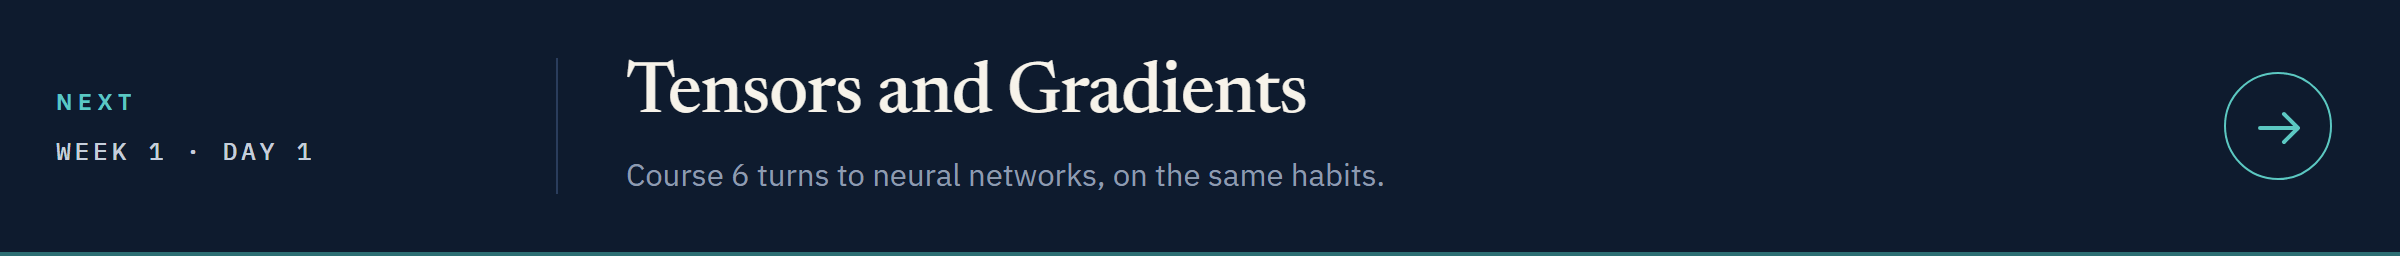](../../../course06_neural_networks/week1/day1/01_tensors_and_gradients.ipynb)

[Open Day 1 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course06_neural_networks/week1/day1/01_tensors_and_gradients.ipynb)